In [1]:
library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(STACAS)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed

‘SeuratObject’ was built with package ‘Matrix’ 1.7.0 but the current
version is 1.7.2; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1    

In [2]:
teich_ad_mtx <- readMM("../../DATA_scRNAseq/Analysis_of_previously_published_data/063_Teichman_colon/pediatric_RAWCOUNTS_cellxgene_c.mtx")

teich_ad_mtx[1:5,1:5]

teich_genes <- read_csv("../../DATA_scRNAseq/Analysis_of_previously_published_data/063_Teichman_colon/pediatric_RAWCOUNTS_cellxgene_c.csv")

teich_metadata <- read_csv("../../DATA_scRNAseq/Analysis_of_previously_published_data/063_Teichman_colon/pediatric_RAWCOUNTS_cellxgene_c_ad_meta.csv")

#teich_genes
#teich_metadata

5 x 5 sparse Matrix of class "dgTMatrix"
              
[1,] . . . . .
[2,] . . . . .
[3,] . . . . .
[4,] . . . . .
[5,] . . . . .

Rows: 33694 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): index, gene_ids

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 22502 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (7): Diagnosis, Sample name, Type, batch, annotation_V2, inferred state,...
dbl (5): Age, doublet_scores, n_genes, percent_mito, n_counts
lgl (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
teich_metadata

Age,Diagnosis,Sample name,Type,batch,doublet_scores,predicted_doublets,n_genes,percent_mito,n_counts,annotation_V2,inferred state,category
<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.009254499,FALSE,1064,0.04792479,4361,CD4 T cell,CD,T cells
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.058430718,FALSE,1995,0.33995390,5639,TA,CD,Epithelial
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.012441250,FALSE,997,0.02212933,4067,CD4 T cell,CD,T cells
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.008289375,FALSE,1120,0.03226607,4029,CD4 T cell,CD,T cells
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.050025265,FALSE,3783,0.07926623,14773,TA,CD,Epithelial
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.012441250,FALSE,1652,0.02852296,9431,IgA plasma cell,CD,Plasma cells
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.014847162,FALSE,1227,0.51309365,4506,Goblet cell,CD,Epithelial
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.098321343,FALSE,5919,0.18469745,29995,TA,CD,Epithelial
13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.011326861,FALSE,1919,0.01886013,14528,IgG plasma cell,CD,Plasma cells


In [4]:
teich_genes

index,gene_ids
<chr>,<chr>
RP11-34P13.3,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
RP11-34P13.14,ENSG00000239906
RP11-34P13.9,ENSG00000241599
FO538757.3,ENSG00000279928
FO538757.2,ENSG00000279457


In [5]:
duplicated(teich_genes$index)  %>% table

.
FALSE 
33694 

In [6]:
rownames(teich_ad_mtx)  <- paste0("bc_",1:nrow(teich_ad_mtx))
colnames(teich_ad_mtx) <- teich_genes$index

In [7]:
teich_ad_mtx2 <- t(teich_ad_mtx)

In [8]:
teich_ad_mtx2[1:5,1:5]

5 x 5 sparse Matrix of class "dgTMatrix"
             bc_1 bc_2 bc_3 bc_4 bc_5
RP11-34P13.3    .    .    .    .    .
FAM138A         .    .    .    .    .
OR4F5           .    .    .    .    .
RP11-34P13.7    .    .    .    .    .
RP11-34P13.8    .    .    .    .    .

In [9]:
rownames(teich_metadata) <- rownames(teich_ad_mtx) 

Warning message:
“Setting row names on a tibble is deprecated.”


In [11]:
teich_metadata  <- as.data.frame(teich_metadata)

In [13]:
rownames(teich_metadata) <- rownames(teich_ad_mtx) 

In [14]:
teich_metadata

,Age,Diagnosis,Sample name,Type,batch,doublet_scores,predicted_doublets,n_genes,percent_mito,n_counts,annotation_V2,inferred state,category
,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
bc_1,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.009254499,FALSE,1064,0.04792479,4361,CD4 T cell,CD,T cells
bc_2,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.058430718,FALSE,1995,0.33995390,5639,TA,CD,Epithelial
bc_3,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.012441250,FALSE,997,0.02212933,4067,CD4 T cell,CD,T cells
bc_4,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.008289375,FALSE,1120,0.03226607,4029,CD4 T cell,CD,T cells
bc_5,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.050025265,FALSE,3783,0.07926623,14773,TA,CD,Epithelial
bc_6,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.012441250,FALSE,1652,0.02852296,9431,IgA plasma cell,CD,Plasma cells
bc_7,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.014847162,FALSE,1227,0.51309365,4506,Goblet cell,CD,Epithelial
bc_8,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.098321343,FALSE,5919,0.18469745,29995,TA,CD,Epithelial
bc_9,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.011326861,FALSE,1919,0.01886013,14528,IgG plasma cell,CD,Plasma cells


In [15]:
seu_teich <- CreateSeuratObject(teich_ad_mtx2, meta.data = teich_metadata, min.cells = 3, min.features = 200)

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message:
“Data is of class dgTMatrix. Coercing to dgCMatrix.”


In [16]:
seu_teich$bc <- colnames(seu_teich)

## Processing full object

In [21]:
seu_teich <- NormalizeData(seu_teich, verbose = FALSE)
seu_teich <- FindVariableFeatures(seu_teich, nfeatures = 1000, verbose = FALSE)
seu_teich <- ScaleData(seu_teich, verbose = FALSE)
seu_teich <- RunPCA(seu_teich, npcs = 10, verbose = FALSE)
seu_teich <- RunUMAP(seu_teich, reduction = "pca", dims = 1:10)
seu_teich <- FindNeighbors(seu_teich, dims = 1:10)
seu_teich <- FindClusters(seu_teich, resolution = 0.3)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
16:01:21 UMAP embedding parameters a = 0.9922 b = 1.112

16:01:21 Read 22502 rows and found 10 numeric columns

16:01:21 Using Annoy for neighbor search, n_neighbors = 30

16:01:21 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:01:25 Writing NN index file to temp file /home/vercanie/R/tmp//Rtmpo6RoA8/file270bc748e9c265

16:01:25 Searching Annoy index using 1 thread, search_k = 3000

16:01:34 Annoy recall = 100%

16:01:36 Commencing smooth kNN distance calibration using 1 thread
 with 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 22502
Number of edges: 748884

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9564
Number of communities: 13
Elapsed time: 4 seconds


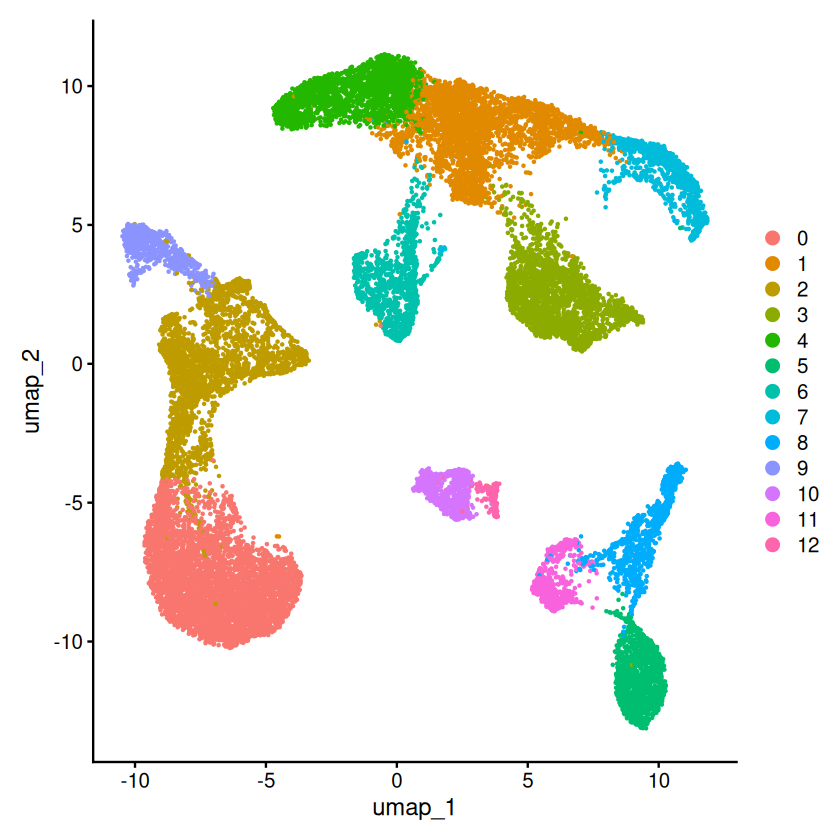

In [22]:
DimPlot(seu_teich)

In [23]:
seu_teich@meta.data  %>% colnames

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "Age"                "Diagnosis"          "Sample name"       
 [7] "Type"               "batch"              "doublet_scores"    
[10] "predicted_doublets" "n_genes"            "percent_mito"      
[13] "n_counts"           "annotation_V2"      "inferred state"    
[16] "category"           "bc"                 "RNA_snn_res.0.3"   
[19] "seurat_clusters"

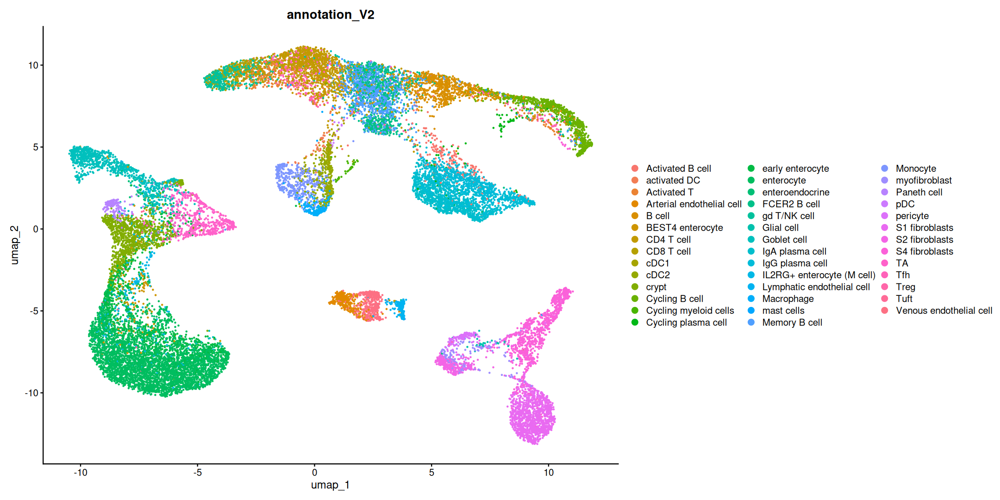

In [28]:
options(repr.plot.width = 18, repr.plot.height = 9)
DimPlot(seu_teich, group.by = "annotation_V2")

Warning message:
“ggrepel: 3 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


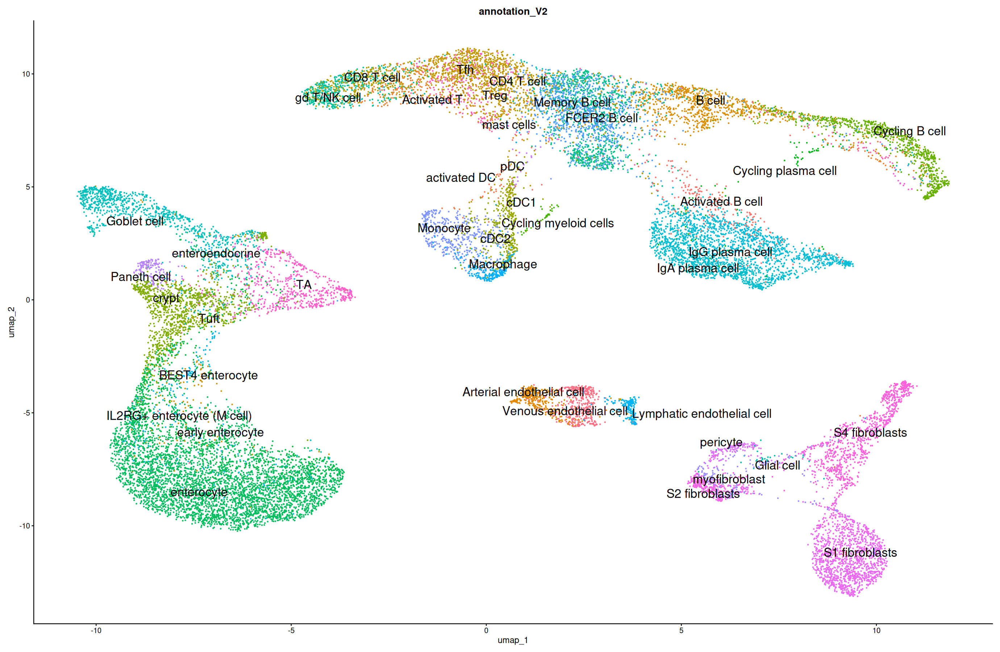

In [32]:
options(repr.plot.width = 23, repr.plot.height = 15)
DimPlot(seu_teich, group.by = "annotation_V2", label = T, label.size = 7, repel = T) + NoLegend()

In [33]:
seu_teich$annotation_V2  %>% table

.
          Activated B cell               activated DC 
                       218                         43 
               Activated T  Arterial endothelial cell 
                       301                        355 
                    B cell           BEST4 enterocyte 
                       845                        119 
                CD4 T cell                 CD8 T cell 
                      1258                        340 
                      cDC1                       cDC2 
                        61                        337 
                     crypt             Cycling B cell 
                      1190                        865 
     Cycling myeloid cells        Cycling plasma cell 
                        40                         78 
          early enterocyte                 enterocyte 
                       837                       4112 
           enteroendocrine               FCER2 B cell 
                        71                       1001 
        

In [34]:
tcells  <- subset(seu_teich, annotation_V2 %in% c("Treg","Tfh", "gd T/NK cell",
                                                  "CD4 T cell", "CD8 T cell",
                                                  "Activated T"))

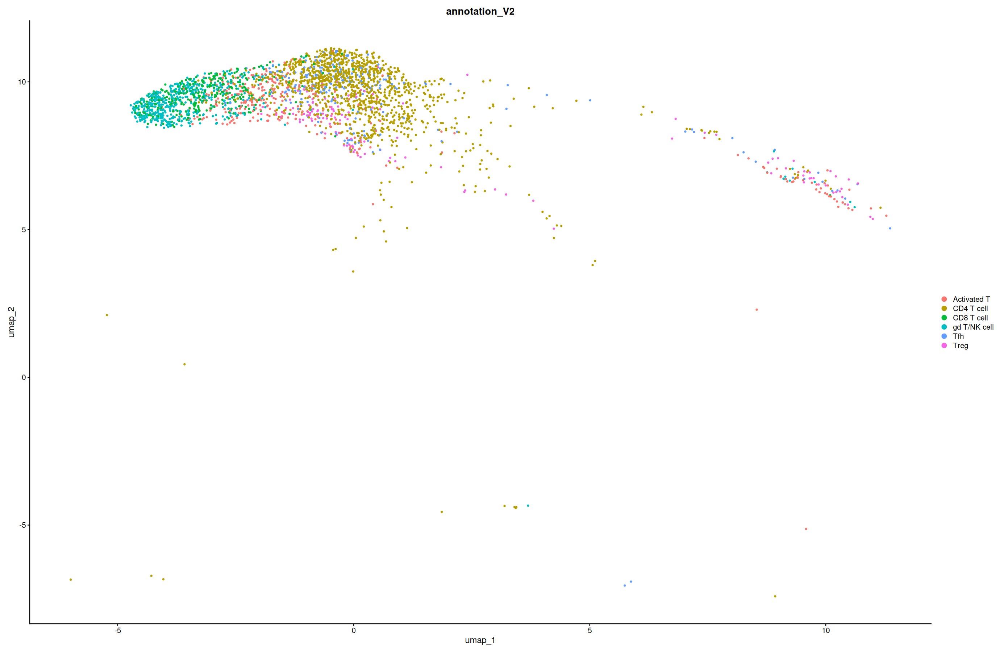

In [36]:
DimPlot(tcells, group.by = "annotation_V2")

In [37]:
tcells <- NormalizeData(tcells, verbose = FALSE)
tcells <- FindVariableFeatures(tcells, nfeatures = 1000, verbose = FALSE)
tcells <- ScaleData(tcells, verbose = FALSE)
tcells <- RunPCA(tcells, npcs = 10, verbose = FALSE)
tcells <- RunUMAP(tcells, reduction = "pca", dims = 1:10)
tcells <- FindNeighbors(tcells, dims = 1:10)
tcells <- FindClusters(tcells, resolution = 0.3)

Warning message:
“Different features in new layer data than already exists for scale.data”
16:09:26 UMAP embedding parameters a = 0.9922 b = 1.112

16:09:26 Read 2758 rows and found 10 numeric columns

16:09:26 Using Annoy for neighbor search, n_neighbors = 30

16:09:26 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:09:26 Writing NN index file to temp file /home/vercanie/R/tmp//Rtmpo6RoA8/file270bc72fe4e267

16:09:26 Searching Annoy index using 1 thread, search_k = 3000

16:09:27 Annoy recall = 100%

16:09:29 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:09:32 Initializing from normalized Laplacian + noise (using RSpectra)

16:09:32 Commencing optimization for 500 epochs, with 112038 positive edges

16:09:37 Optimizatio

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2758
Number of edges: 93531

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9020
Number of communities: 7
Elapsed time: 0 seconds


An object of class Seurat 
24192 features across 2758 samples within 1 assay 
Active assay: RNA (24192 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

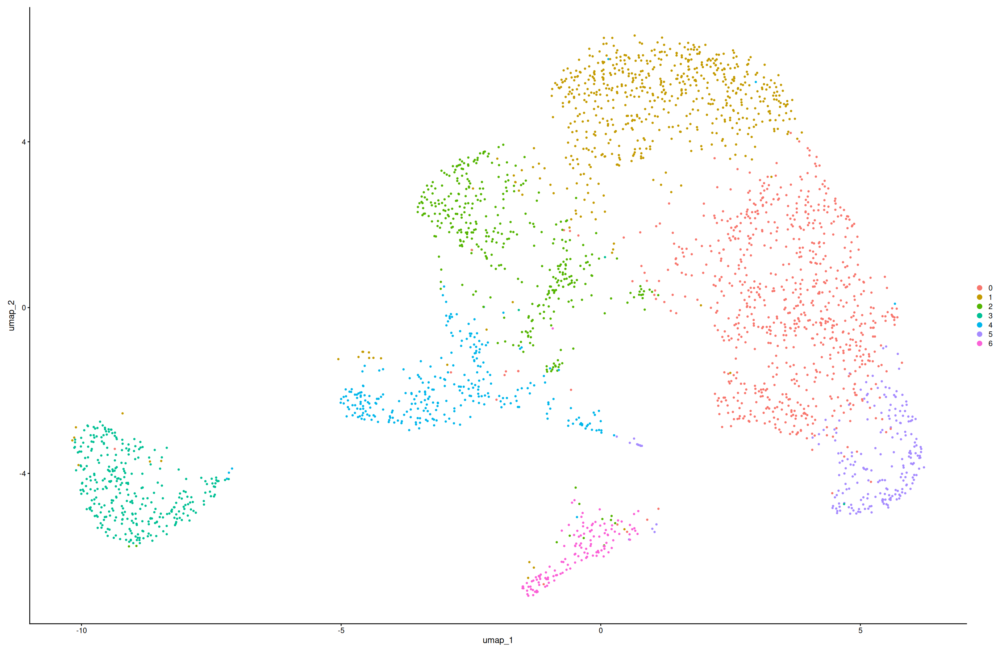

In [39]:
DimPlot(tcells)
tcells

In [40]:
seu_teich$Diagnosis  %>% table

.
 Crohn Disease Normal control 
         11200          11302 

In [41]:
seu_teich$`Sample name`  %>% table

.
T017 T019 T024 T036 T057 T110 T160 T161 T176 T182 T189 T197 T202 T203  T44 
1008 1602 1065 2582 1911 1143  891  957 3430 1254  741 2360 1319  740 1499 

In [42]:
teich_subset <- readRDS("../240202_VN_CD4_CTL_integration/old_data/teich_subset.rds")

In [44]:
teich_subset

An object of class Seurat 
30282 features across 14618 samples within 1 assay 
Active assay: RNA (30282 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

In [45]:
teich_subset$`Sample name`  %>% table

.
   T017    T019    T024    T036    T044    T057 T110NEG    T160    T161    T176 
   1412     764     790    1219     706    1294     719     514     414    1750 
   T182    T197    T202    T203 
    794    1471    2014     757 

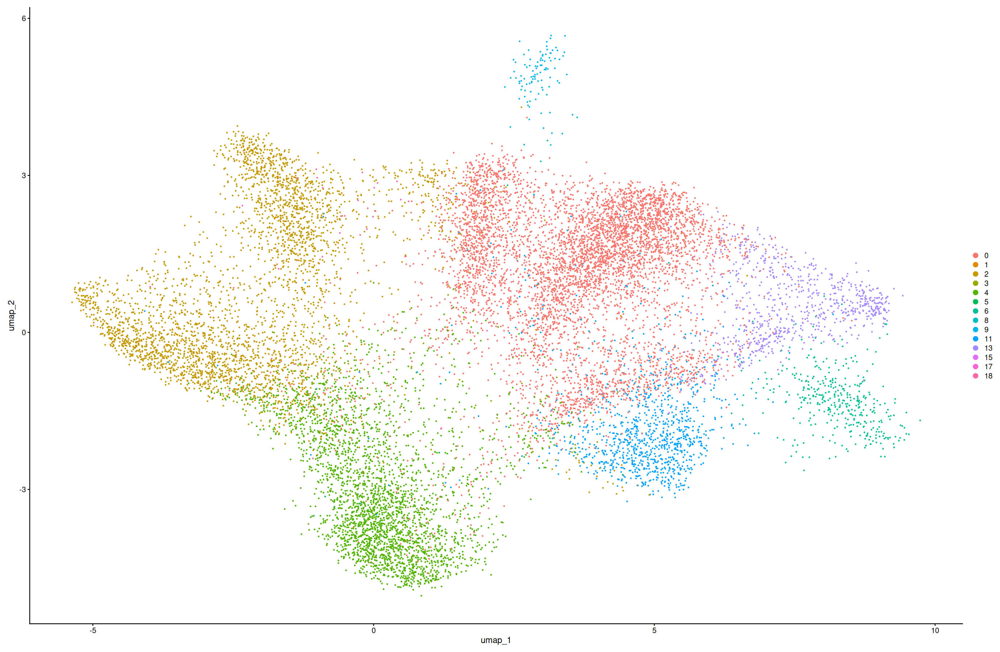

In [43]:
DimPlot(teich_subset)

In [ ]:
teich_subset$annotation

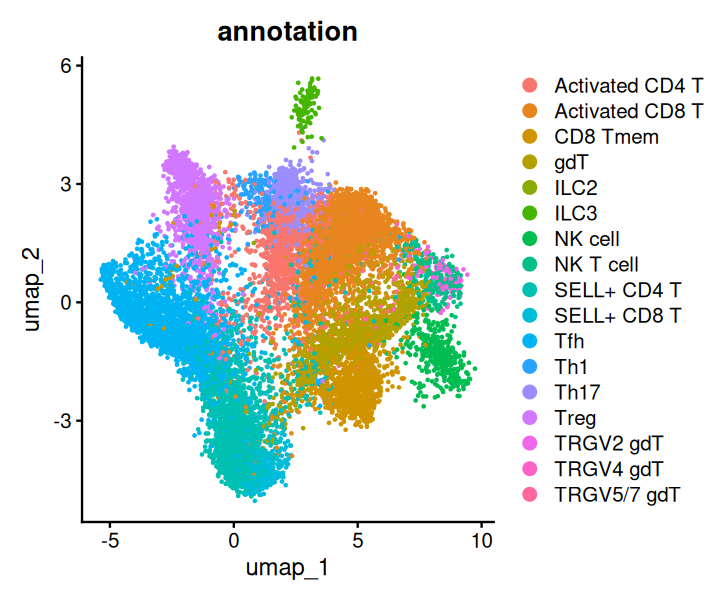

In [52]:
DimPlot(teich_subset, group.by = "annotation")

In [53]:
teich_cd4  <- subset(teich_subset, annotation %in% c("Activated CD4 T", "SELL+ CD4 T",
                                                     "Tfh", "Th1", "Th17", "Treg"))

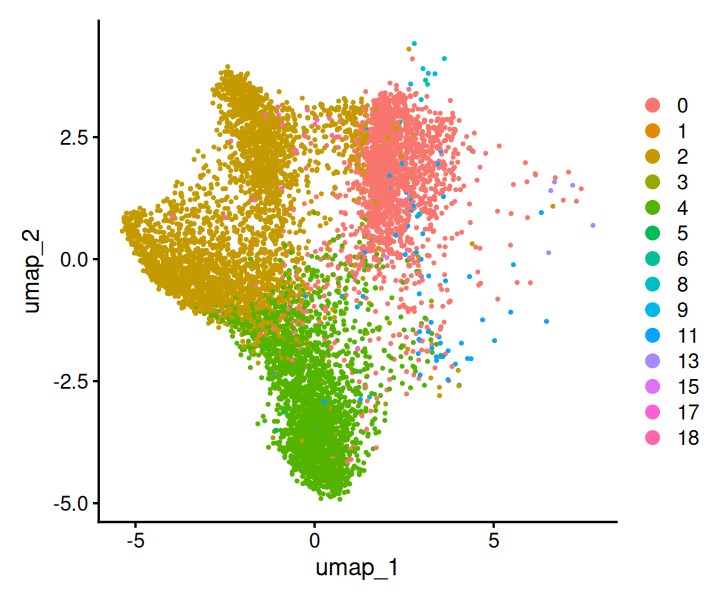

In [54]:
DimPlot(teich_cd4)

In [55]:
teich_cd4 <- NormalizeData(teich_cd4, verbose = FALSE)
teich_cd4 <- FindVariableFeatures(teich_cd4, nfeatures = 1000, verbose = FALSE)
teich_cd4 <- ScaleData(teich_cd4, verbose = FALSE)
teich_cd4 <- RunPCA(teich_cd4, npcs = 10, verbose = FALSE)
teich_cd4 <- RunUMAP(teich_cd4, reduction = "pca", dims = 1:10)
teich_cd4 <- FindNeighbors(teich_cd4, dims = 1:10)
teich_cd4 <- FindClusters(teich_cd4, resolution = 0.3)

Warning message:
“Number of dimensions changing from 50 to 10”
16:20:10 UMAP embedding parameters a = 0.9922 b = 1.112

16:20:10 Read 7865 rows and found 10 numeric columns

16:20:10 Using Annoy for neighbor search, n_neighbors = 30

16:20:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:20:11 Writing NN index file to temp file /home/vercanie/R/tmp//Rtmpo6RoA8/file270bc75b29bf63

16:20:11 Searching Annoy index using 1 thread, search_k = 3000

16:20:14 Annoy recall = 100%

16:20:16 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:20:18 Initializing from normalized Laplacian + noise (using RSpectra)

16:20:19 Commencing optimization for 500 epochs, with 313818 positive edges

16:20:30 Optimization finished

Computing neares

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7865
Number of edges: 237569

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8554
Number of communities: 4
Elapsed time: 1 seconds


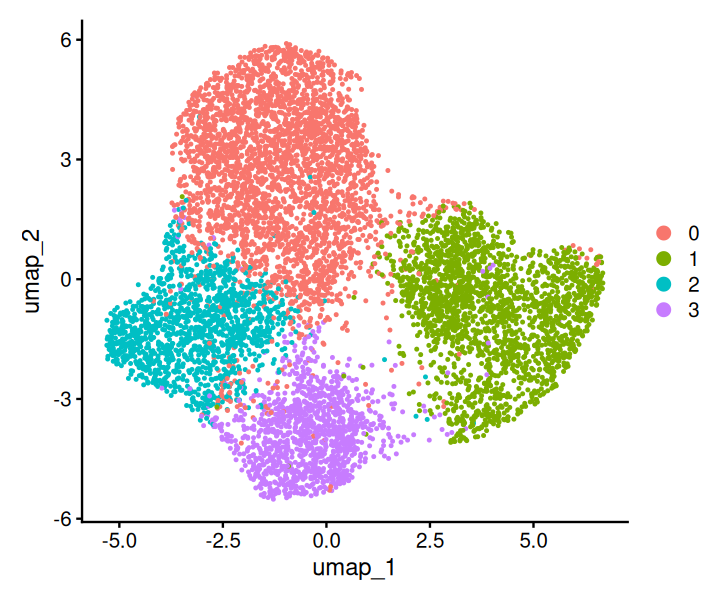

In [56]:
DimPlot(teich_cd4)

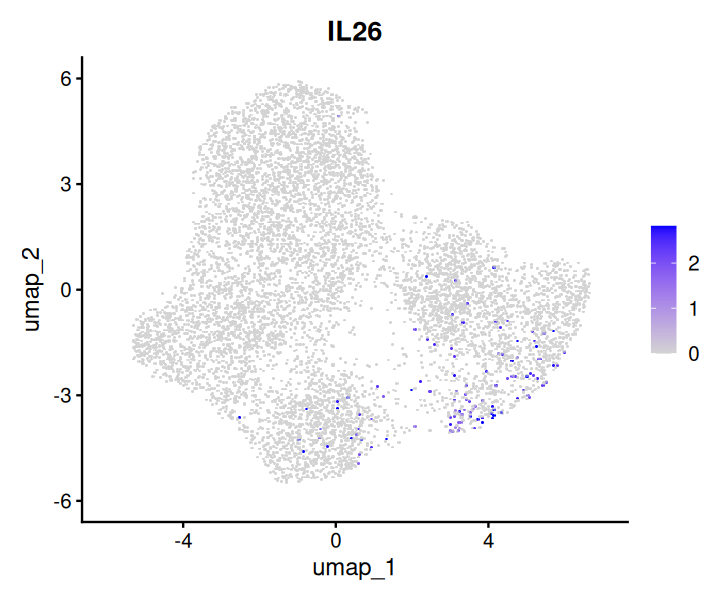

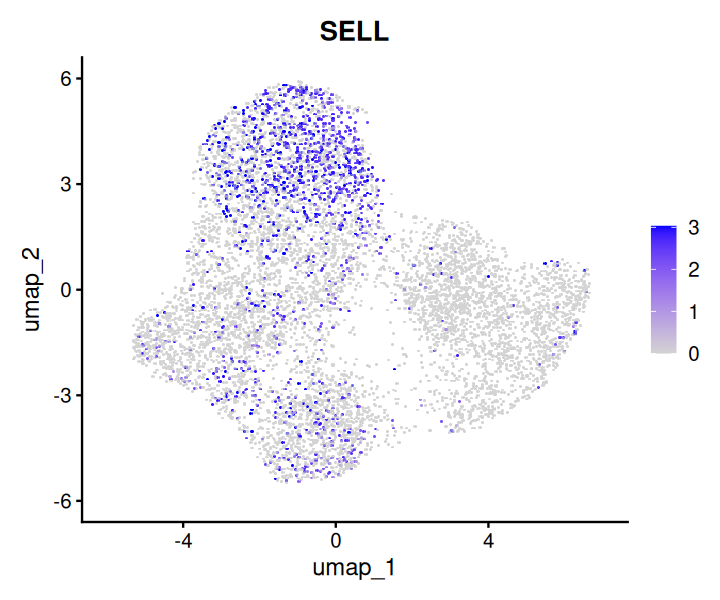

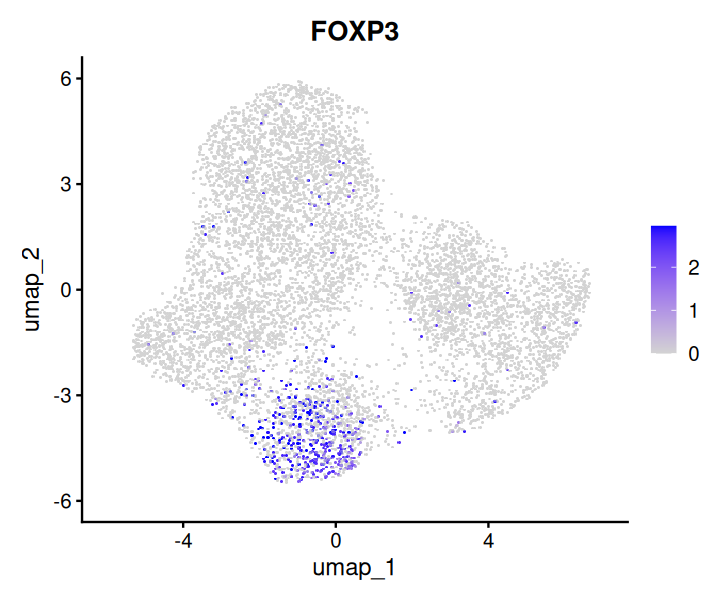

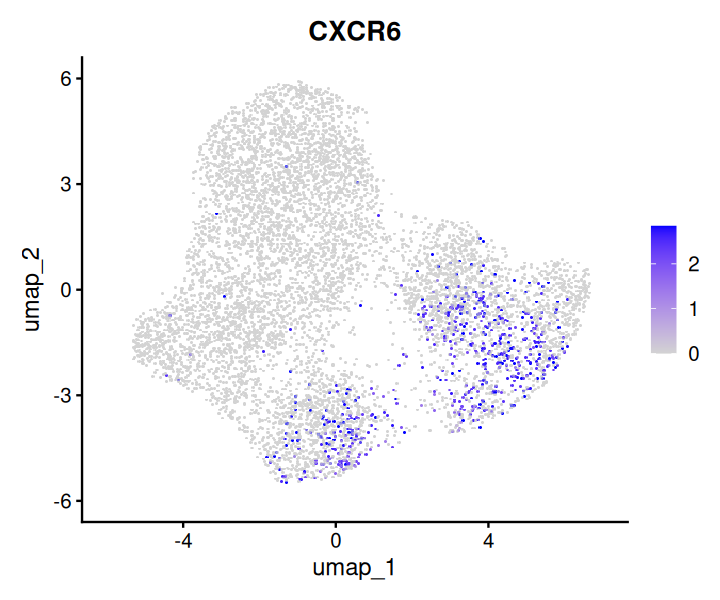

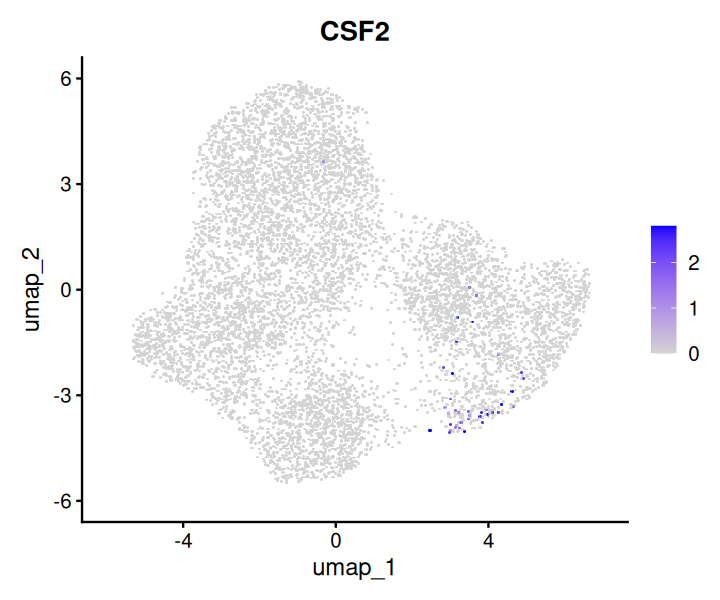

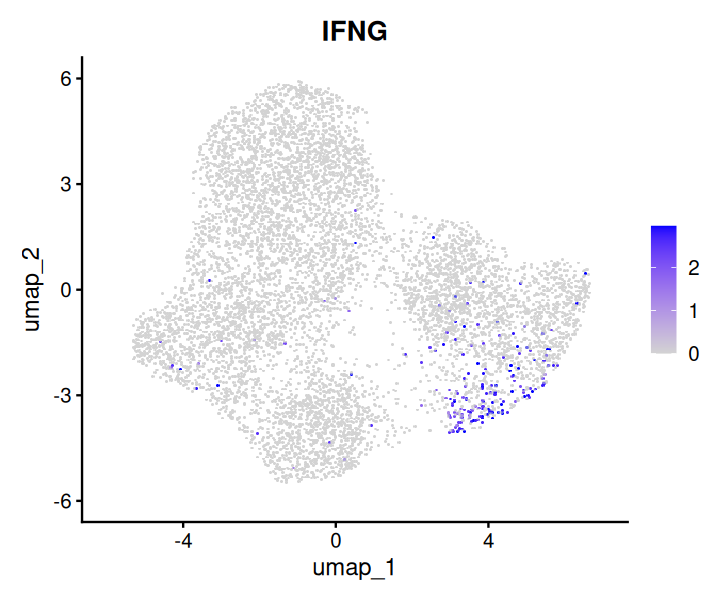

In [59]:

FeaturePlot(teich_cd4, features = "IL26", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "SELL", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "FOXP3", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "CXCR6", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "CSF2", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "IFNG", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)


In [68]:
teich_cd4 <- FindClusters(teich_cd4, resolution = 0.9)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7865
Number of edges: 237569

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7456
Number of communities: 9
Elapsed time: 1 seconds


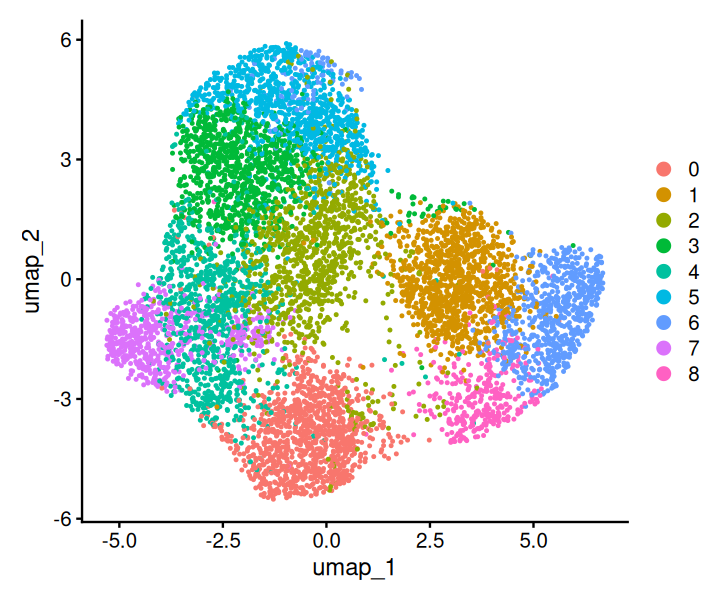

In [69]:
DimPlot(teich_cd4)

# Signature Rios Martini

In [46]:
rioz_sig_100  <- c('GZMH', 'CRTAM', 'CCL3', 'CCL3L1', 'IFNG', 'CCL4L2', 'CCL4', 'IL26', 'GZMB', 'PLEK', 
                   'PRF1', 'XIRP1', 'SLAMF7', 'CA2', 'GNLY', 'HSPA1A', 'PLCB1', 'HSPA1B', 'CD72', 'NKG7', 
                   'SLC4A10', 'IL23R', 'OLFM2', 'HOPX', 'XCL2', 'IQCG', 'XCL1', 'CEBPD', 'SIPA1L2', 'IKZF2', 
                   'ROR2', 'IL18RAP', 'ACSL6', 'GZMA', 'IL12RB2', 'TNFSF9', 'IL3', 'IRF8', 'C11orf96', 
                   'KIAA1217', 'GCNA', 'ETV7', 'CXXC5', 'CCL20', 'RHOU', 'TBX21', 'AFF3', 'IL23A', 'PROK2', 
                   'PXDC1', 'RGS2', 'ZBED2', 'TNFSF13B', 'SOD2', 'RDH10', 'SDC4', 'CD274', 'C2CD4A', 
                   'C2CD4B', 'VAV3', 'CASS4', 'SRD5A3', 'IGF2R', 'APOBEC3G', 'SEMA7A', 'EPAS1', 'IGF2.1', 
                   'GBP5', 'FASLG', 'NLRP3', 'IRF4', 'CKB', 'AIM2', 'MCOLN2', 'GOLIM4', 'CXCR6', 'METRNL', 
                   'IL2', 'TESK1', 'NFE2L3', 'CFL2', 'CSF2', 'AC015912.3', 'ENC1', 'C15orf48', 'HBEGF', 
                   'DUSP6', 'SYTL2', 'SMOX', 'TNFRSF9', 'BIRC3', 'CCL5', 'SATB1', 'MPP1', 'PDE4B', 'IFIT3', 
                   'DDAH2', 'APOBEC3C', 'RGS1', 'TRBV5-4')

In [70]:
rioz_sig_75  <- rioz_sig_100[1:75]


teich_subset  <- AddModuleScore(
  object = teich_cd4,
  features = list(c(rioz_sig_75)),
  search = F,
  assay = "RNA",
  name = 'Rioz_Sig_75_')

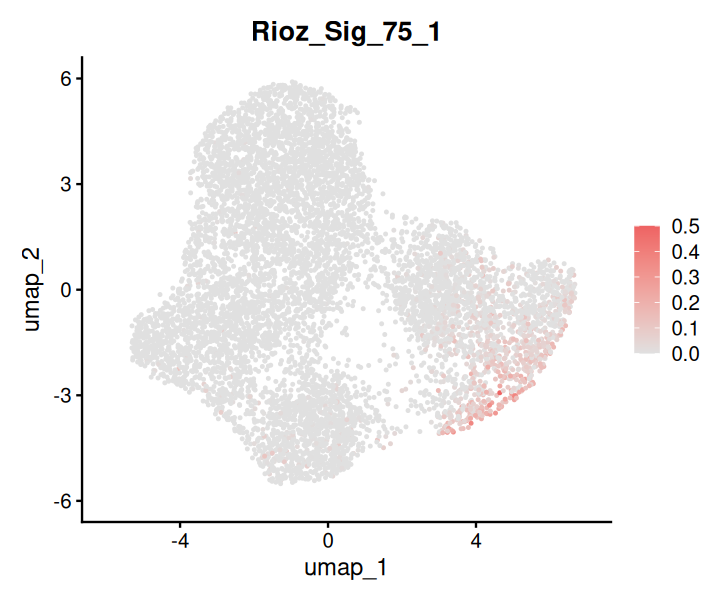

In [73]:
options(repr.plot.width = 6, repr.plot.height = 5)
FeaturePlot(teich_cd4, features = "Rioz_Sig_75_1", min.cutoff = 0, max.cutoff = 0.5, cols = c("grey88","indianred2"))

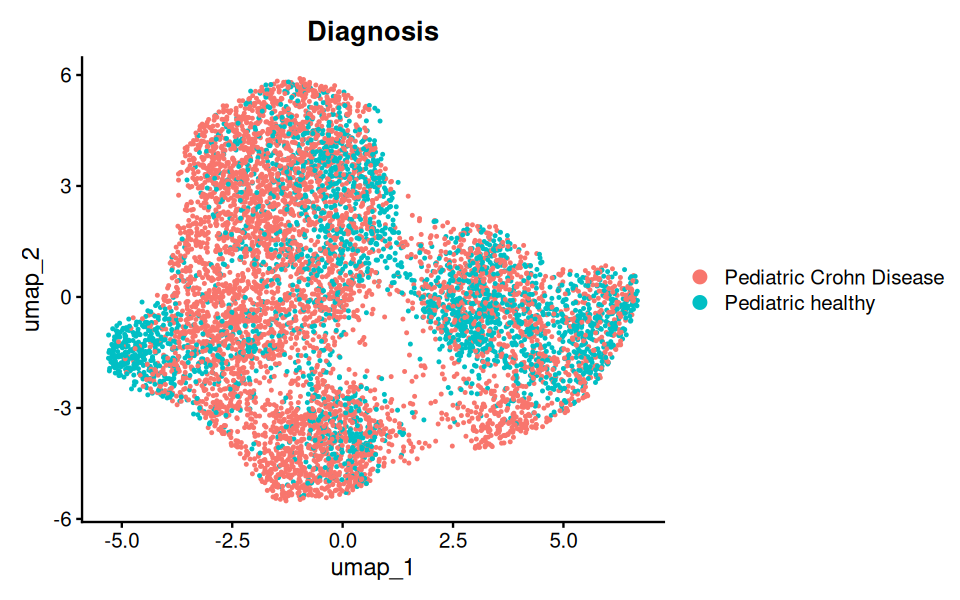

In [79]:
options(repr.plot.width = 8, repr.plot.height = 5)
DimPlot(teich_cd4, group.by = "Diagnosis")

In [80]:
teich_cd4$Patient_ID  <-  teich_cd4$`Sample name`

# Cluster frequency

In [164]:
options(repr.plot.width = 25, repr.plot.height = 10)

seurat_meta_data <- teich_cd4@meta.data

# Create grouped dataframe, calculate the frequencies of clusters
df4 <- seurat_meta_data %>% 
  group_by(Patient_ID, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!Patient_ID, names_to = "seurat_clusters", values_to = "freq")

# Control - all sums should be one
# df4 %>% group_by(MouseID) %>% summarise(sum = sum(freq))

# As we've lost non-grouping variables, let's join them back
md_to_join <- seurat_meta_data %>% 
  dplyr::select(Patient_ID, Diagnosis) %>% 
  unique()

df4  <- left_join(df4, md_to_join)

`summarise()` has grouped output by 'Patient_ID'. You can override using the
`.groups` argument.
Joining with `by = join_by(Patient_ID)`


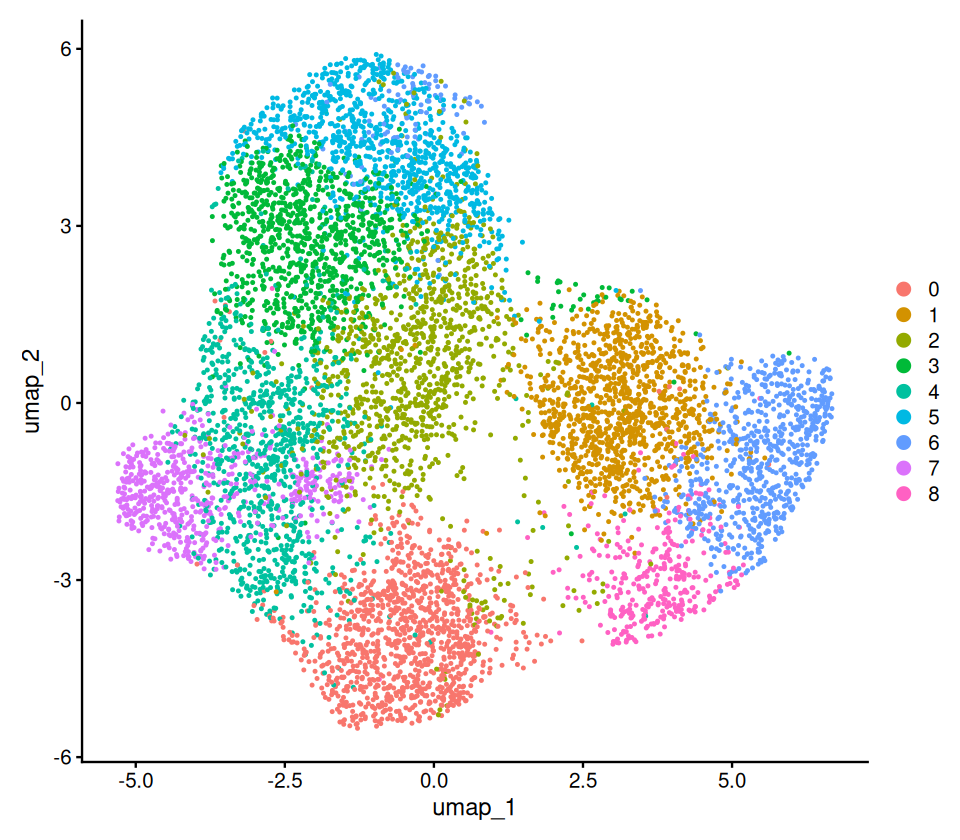

In [112]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(teich_cd4, label = F, label.size = 7)

Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


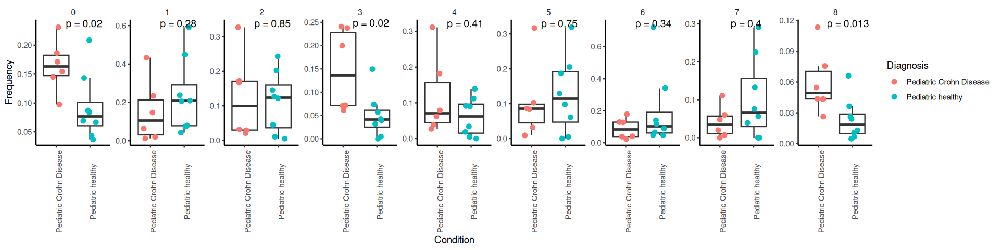

In [165]:
options(repr.plot.width = 16, repr.plot.height = 4)


df4 %>% 
  ggplot(aes(x = Diagnosis, y = freq)) + # you can change the x to whatever variable you're interested in
  geom_boxplot(outlier.shape = NA) + 
  geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
  geom_jitter(position=position_jitter(0.2), size = 2, aes(color = Diagnosis)) + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 9) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90)) +
ggpubr::stat_compare_means(label = "p.format", size = 4, label.x = 1.5) 

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


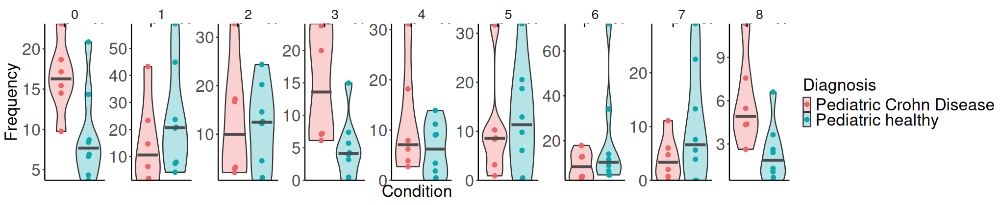

In [184]:
options(repr.plot.width = 17, repr.plot.height = 3.5)


df4 %>% 
  ggplot(aes(x = Diagnosis, y = freq*100)) + # you can change the x to whatever variable you're interested in
    geom_violin(alpha = 0.3, aes(fill = Diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(aes(color = Diagnosis), cex = 2, 
                shape = 16, corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, scales = "free", ncol = 9) +
scale_fill_manual(values = c("indianred2", "#0aa7acff")) +
scale_color_manual(values = c("indianred2", "#0aa7acff")) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
ylim(c(0,NA)) +
scale_y_continuous(expand = c(0,NA)) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()



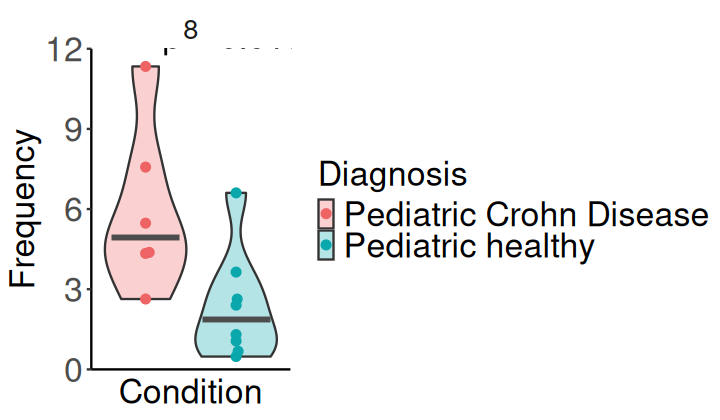

In [187]:
options(repr.plot.width = 6, repr.plot.height = 3.5)


df4 %>% 
dplyr::filter(seurat_clusters == 8)  %>% 
  ggplot(aes(x = Diagnosis, y = freq*100)) + # you can change the x to whatever variable you're interested in
    geom_violin(alpha = 0.3, aes(fill = Diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(aes(color = Diagnosis), cex = 2, 
                shape = 16, corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, scales = "free", ncol = 9) +
scale_fill_manual(values = c("indianred2", "#0aa7acff")) +
scale_color_manual(values = c("indianred2", "#0aa7acff")) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
scale_y_continuous(expand = c(0,NA), limits = c(0,12)) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()


In [189]:
ggsave(filename = "figures/teichman/cluster_frequency_CTL.svg",
      width = 14, height = 7.8, units = "cm")

## Label transfer

In [96]:
gut_cdn.ref <- readRDS("data/mapping_data_onto_predict/gut_cdn_ref.rds")

In [97]:
gut_cdn.anchors <- FindTransferAnchors(reference = gut_cdn.ref, query = teich_cd4,
    dims = 1:12, reference.reduction = "pca")

Projecting cell embeddings

Finding neighborhoods

Finding anchors

	Found 18324 anchors



In [98]:
ref <- MapQuery(anchorset = gut_cdn.anchors, reference = gut_cdn.ref, query = teich_cd4,
    refdata = gut_cdn.ref$annotations, reference.reduction = "pca", reduction.model = "umap")

Finding integration vectors

Finding integration vector weights

Predicting cell labels

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Integrating dataset 2 with reference dataset

Finding integration vectors

Integrating data

Computing nearest neighbors

Running UMAP projection

17:03:40 Read 7865 rows

17:03:40 Processing block 1 of 1

17:03:40 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:03:40 Initializing by weighted average of neighbor coordinates using 1 thread

17:03:41 Commencing optimization for 67 epochs, with 235950 positive edges

17:03:42 Finished



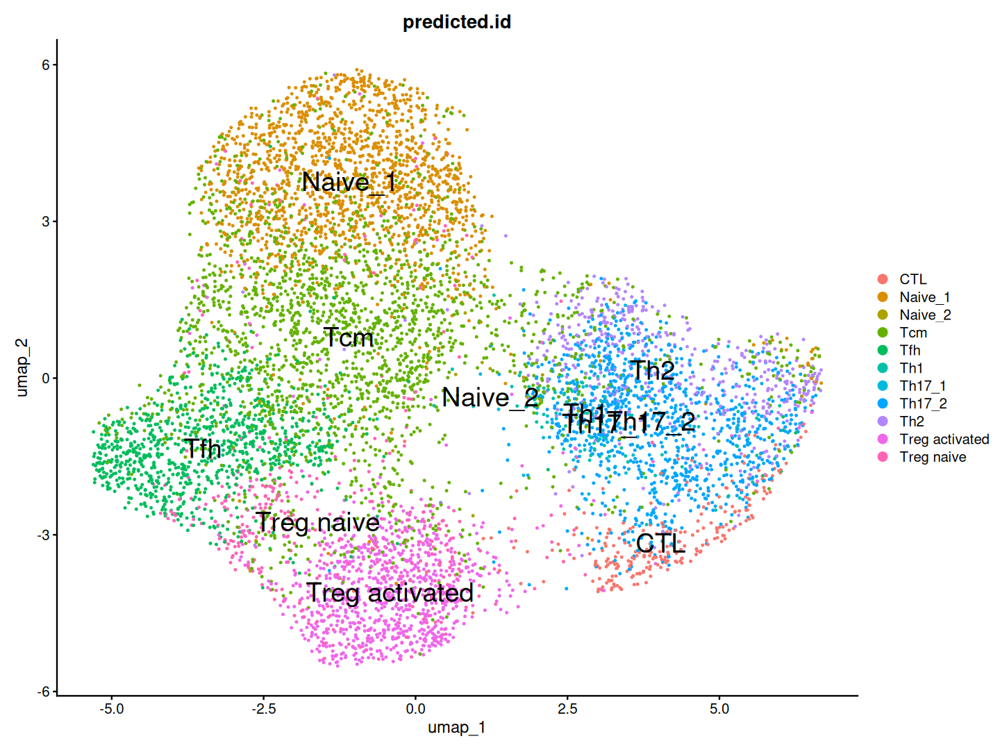

In [99]:
options(repr.plot.width = 12, repr.plot.height = 9)
DimPlot(ref, group.by = "predicted.id", label = T, label.size = 8)

In [104]:
saveRDS(ref, "data/mapping_data_onto_predict/teichman_query.rds")

`summarise()` has grouped output by 'Patient_ID'. You can override using the
`.groups` argument.
Joining with `by = join_by(Patient_ID)`
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


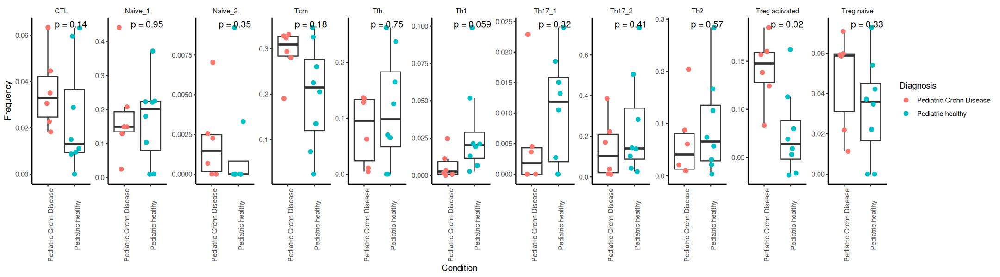

In [105]:
options(repr.plot.width = 18, repr.plot.height = 5)

seurat_meta_data <- ref@meta.data

# Create grouped dataframe, calculate the frequencies of clusters
df4 <- seurat_meta_data %>% 
  group_by(Patient_ID, predicted.id) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = predicted.id, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!Patient_ID, names_to = "seurat_clusters", values_to = "freq")

# Control - all sums should be one
# df4 %>% group_by(MouseID) %>% summarise(sum = sum(freq))

# As we've lost non-grouping variables, let's join them back
md_to_join <- seurat_meta_data %>% 
  dplyr::select(Patient_ID, Diagnosis) %>% 
  unique()

df4  <- left_join(df4, md_to_join)


df4 %>% 
  ggplot(aes(x = Diagnosis, y = freq)) + # you can change the x to whatever variable you're interested in
  geom_boxplot(outlier.shape = NA) + 
  geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
  geom_jitter(position=position_jitter(0.2), size = 2, aes(color = Diagnosis)) + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 11) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90)) +
ggpubr::stat_compare_means(label = "p.format", size = 4, label.x = 1.5) 

In [153]:
df2 <- ref@meta.data %>% group_by(predicted.id, seurat_clusters) %>% 
  summarise(n = n()) %>%
  mutate(freq = n / sum(n))

g2 <- ggplot(df2, aes(factor(predicted.id, levels = rev(c(
"Naive_1","Naive_2","Tcm","Tfh","Treg naive", "Treg activated", "Th1","Th2","Th17_1","Th17_2","CTL"))),
                      seurat_clusters)) + 
  geom_point(aes(size = freq*100, colour = freq*100)) + 
  theme_bw() +
  scale_size_continuous(range=c(5,10)) +
  geom_text(aes(label = round(freq*100, digits = 1))) + 
  scale_colour_gradient2(low = "lightskyblue", mid = "lightsteelblue2", high = "salmon", midpoint = 2) +
  theme_bw() + xlab("") + ylab("") +
theme(axis.text = element_text(color = "black"))

`summarise()` has grouped output by 'predicted.id'. You can override using the
`.groups` argument.


In [110]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

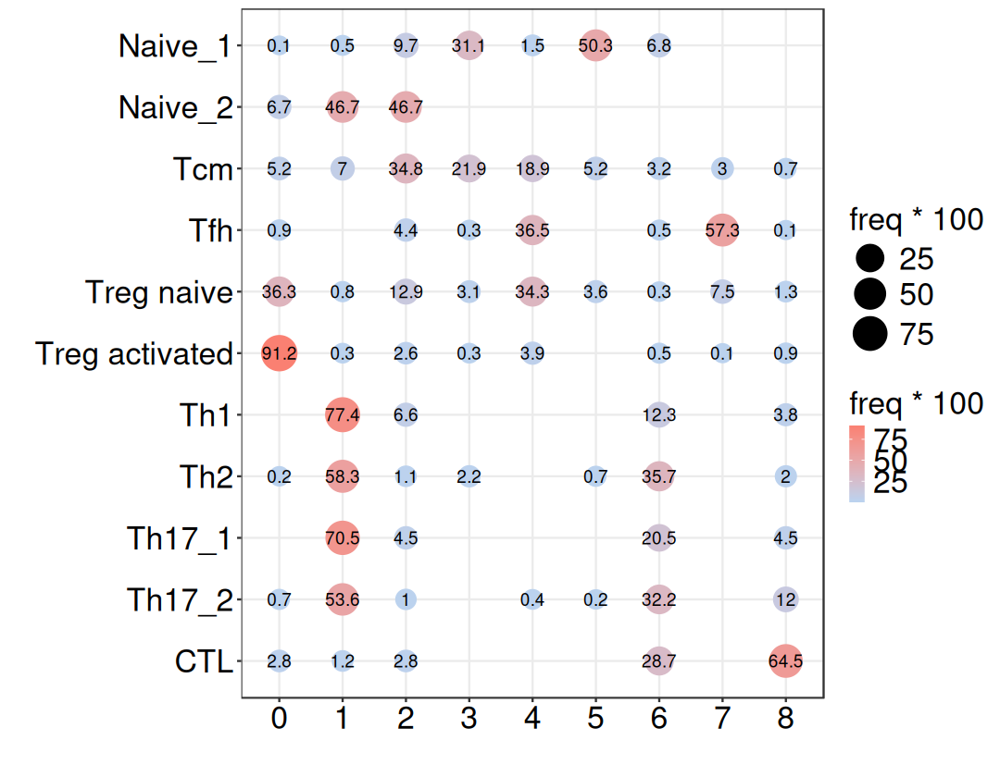

In [154]:
options(repr.plot.width = 9, repr.plot.height = 7)
g2 +coord_flip() + ggtheme()

In [156]:
ggsave("figures/teichman/predicted_id_clusters.svg", width = 7.5, height = 4.5, create.dir = T)

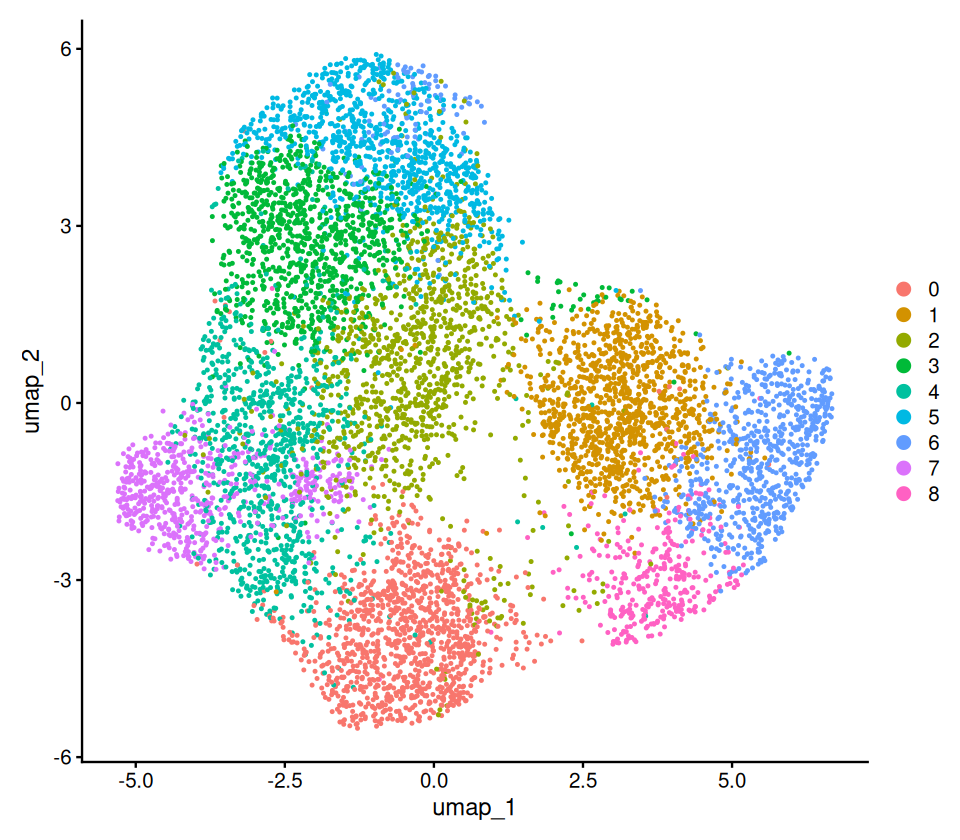

In [115]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(teich_cd4, label = F, label.size = 7)

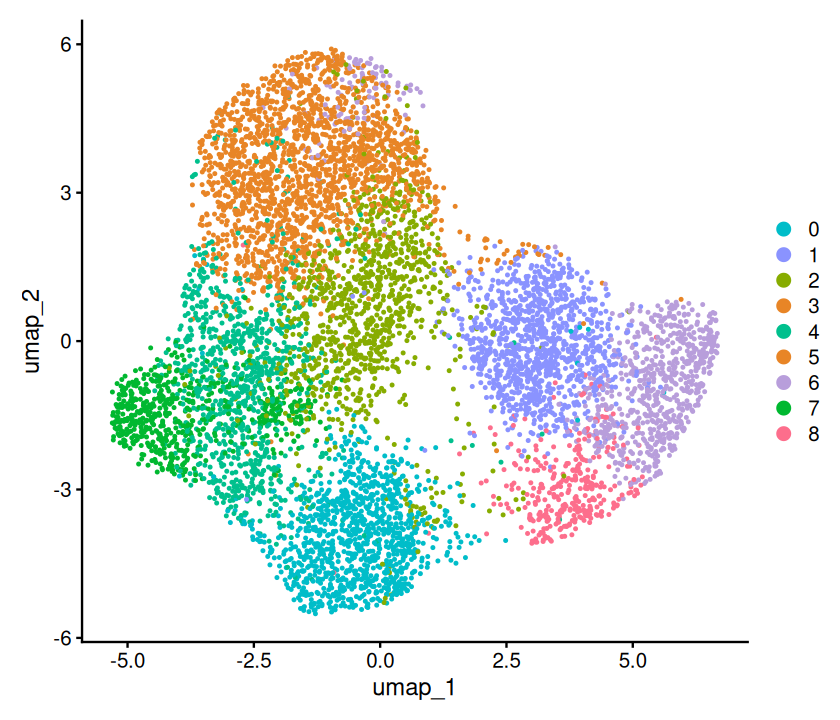

In [118]:
options(repr.plot.width = 7, repr.plot.height = 6)

DimPlot(teich_cd4, label = F, label.size = 7) +
scale_color_manual(values = c("0" = "#00bdc9ff",
                              "1" = "#8a93ffff",
                              "2" = "#87ac00ff",
                              "3" = "#e88526ff",
                              "4" = "#00c08dff",
                             "5" = "#e88526ff",
                             "6" = "#b89edbff",
                             "7" = "#00b830ff",
                             "8" = "#fd6e8cff"
                             ))

In [119]:
teich_cd4

An object of class Seurat 
30282 features across 7865 samples within 1 assay 
Active assay: RNA (30282 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

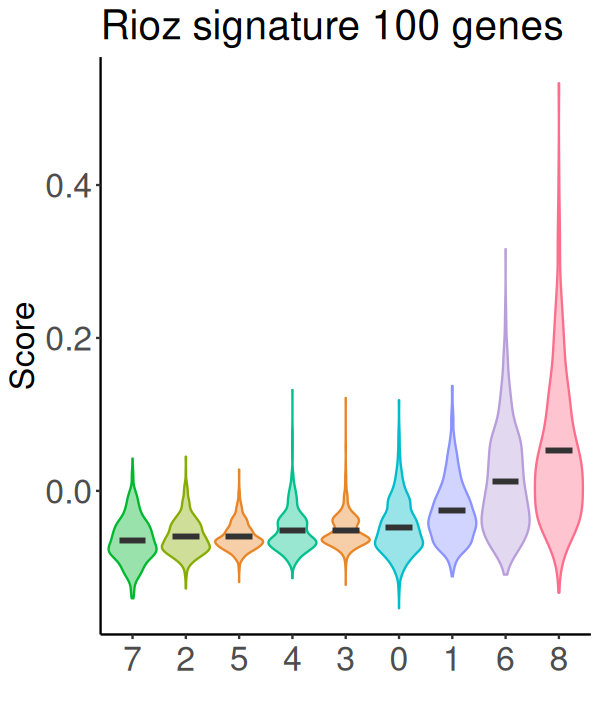

In [148]:
options(repr.plot.width = 5, repr.plot.height =6)
ggplot(data.frame(Score = teich_cd4$Rioz_Sig_75_1,
                  Annotation = as.factor(teich_cd4$seurat_clusters)), 
       aes(x = reorder(Annotation, X = Score, FUN = mean), y = Score)) +
  geom_violin(scale = "width", aes(color = Annotation, fill = Annotation), alpha = 0.4) + 
  stat_summary(fun = "mean",
               geom = "crossbar", 
               width = 0.5,
               colour = "grey20") + ggtitle("Rioz signature 100 genes") +
theme_classic() +
xlab("") + ggtheme() + theme(axis.text.x = element_text(angle = 0, hjust = 0.5, vjust = 0.5)) +
scale_color_manual(values = c("0" = "#00bdc9ff",
                              "1" = "#8a93ffff",
                              "2" = "#87ac00ff",
                              "3" = "#e88526ff",
                              "4" = "#00c08dff",
                             "5" = "#e88526ff",
                             "6" = "#b89edbff",
                             "7" = "#00b830ff",
                             "8" = "#fd6e8cff"
                             )) +
scale_fill_manual(values = c("0" = "#00bdc9ff",
                              "1" = "#8a93ffff",
                              "2" = "#87ac00ff",
                              "3" = "#e88526ff",
                              "4" = "#00c08dff",
                             "5" = "#e88526ff",
                             "6" = "#b89edbff",
                             "7" = "#00b830ff",
                             "8" = "#fd6e8cff"
                             )) + ggtheme() + NoLegend()

In [149]:
ggsave("figures/teichman/rios_sig_clusters.svg", width = 4, height = 4.5, create.dir = T)

In [160]:
marker_genes  <- c("IL26","IL17F","GZMA","GZMB","GNLY","CXCR6","PRF1","IL13","IFNG",
                   "RORC","IL17A","IL23R","IL22","TNF","RORA","TBX21",'CSF2', 'IL12RB2')
  

In [161]:
avgexp = AverageExpression(ref, features = marker_genes, group.by = "seurat_clusters",
                          assay = "RNA")

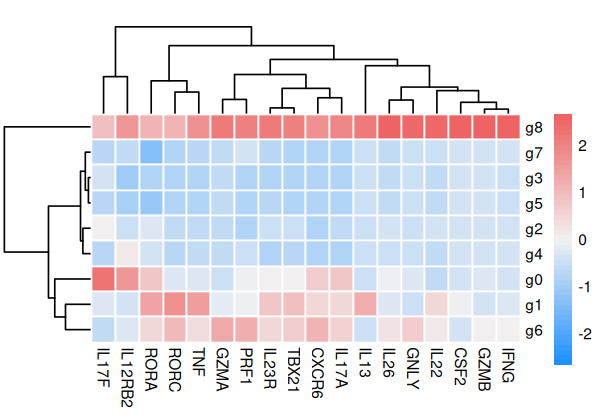

In [162]:
options(repr.plot.width = 5, repr.plot.height = 3.5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [163]:
options(repr.plot.width = 5, repr.plot.height = 3.5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 6, height = 5, 
                  filename = "figures/teichman/heatmap.pdf")

## Correlation

In [191]:
seu_teich@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,Age,Diagnosis,Sample name,Type,batch,doublet_scores,predicted_doublets,n_genes,percent_mito,n_counts,annotation_V2,inferred state,category,bc,RNA_snn_res.0.3,seurat_clusters
,<fct>,<dbl>,<int>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
bc_1,bc,4361,1064,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.009254499,FALSE,1064,0.04792479,4361,CD4 T cell,CD,T cells,bc_1,1,1
bc_2,bc,5639,1994,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.058430718,FALSE,1995,0.33995390,5639,TA,CD,Epithelial,bc_2,2,2
bc_3,bc,4067,997,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.012441250,FALSE,997,0.02212933,4067,CD4 T cell,CD,T cells,bc_3,4,4
bc_4,bc,4029,1120,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.008289375,FALSE,1120,0.03226607,4029,CD4 T cell,CD,T cells,bc_4,4,4
bc_5,bc,14773,3783,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.050025265,FALSE,3783,0.07926623,14773,TA,CD,Epithelial,bc_5,2,2
bc_6,bc,9431,1652,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.012441250,FALSE,1652,0.02852296,9431,IgA plasma cell,CD,Plasma cells,bc_6,3,3
bc_7,bc,4506,1227,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.014847162,FALSE,1227,0.51309365,4506,Goblet cell,CD,Epithelial,bc_7,2,2
bc_8,bc,29995,5918,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.098321343,FALSE,5919,0.18469745,29995,TA,CD,Epithelial,bc_8,2,2
bc_9,bc,14528,1919,13,Crohn Disease,T017,Paediatric biopsy,4918STDY7273964,0.011326861,FALSE,1919,0.01886013,14528,IgG plasma cell,CD,Plasma cells,bc_9,3,3


In [192]:
seu_teich$sample_id  <- seu_teich$`Sample name`

In [ ]:
seu_teich$annotation_V2

In [234]:
df_populations  <- seu_teich@meta.data  %>% 
group_by(sample_id, annotation_V2) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
dplyr::filter(annotation_V2 != "")  %>% 
pivot_wider(names_from = annotation_V2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sample_id, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'sample_id'. You can override using the
`.groups` argument.


In [235]:
df_populations

sample_id,celltypes,freq
<chr>,<chr>,<dbl>
T017,Activated B cell,0.0009920635
T017,Activated T,0.0148809524
T017,Arterial endothelial cell,0.0357142857
T017,B cell,0.0257936508
T017,BEST4 enterocyte,0.0009920635
T017,CD4 T cell,0.1121031746
T017,CD8 T cell,0.0009920635
T017,Cycling B cell,0.0555555556
T017,Cycling plasma cell,0.0019841270


In [236]:
teich_cd4$sample_id  <- teich_cd4$`Sample name`
teich_cd4$annotation_V2  <- teich_cd4$seurat_clusters

In [237]:
df_tcells  <- teich_cd4@meta.data  %>% 
group_by(sample_id, annotation_V2) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
dplyr::filter(annotation_V2 != "")  %>% 
pivot_wider(names_from = annotation_V2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sample_id, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'sample_id'. You can override using the
`.groups` argument.


In [238]:
populations  <- levels(factor(df_tcells$celltypes))

In [239]:
df_populations$celltypes  %>% table  %>% length

[1] 41

In [240]:
df_populations$celltypes  %>% table

.
          Activated B cell               activated DC 
                        15                         15 
               Activated T  Arterial endothelial cell 
                        15                         15 
                    B cell           BEST4 enterocyte 
                        15                         15 
                CD4 T cell                 CD8 T cell 
                        15                         15 
                      cDC1                       cDC2 
                        15                         15 
                     crypt             Cycling B cell 
                        15                         15 
     Cycling myeloid cells        Cycling plasma cell 
                        15                         15 
          early enterocyte                 enterocyte 
                        15                         15 
           enteroendocrine               FCER2 B cell 
                        15                         15 
        

In [241]:
populations

[1] "0" "1" "2" "3" "4" "5" "6" "7" "8"

In [242]:
i = 1
to_join <- df_tcells  %>% dplyr::filter(celltypes == levels(factor(df_tcells$celltypes))[i])  %>% 
dplyr::select(sample_id, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*41>1,1,p*41))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])

Joining with `by = join_by(sample_id)`


In [243]:
stat_test  %>% arrange(p.adj)

celltypes,p.adj,cor,seurat_clusters
<chr>,<dbl>,<dbl>,<chr>
activated DC,0.32595,0.720,0
IgG plasma cell,0.32677,0.720,0
Cycling plasma cell,0.50430,0.690,0
Monocyte,0.77080,0.660,0
S4 fibroblasts,1.00000,0.560,0
pericyte,1.00000,0.490,0
cDC1,1.00000,0.470,0
pDC,1.00000,0.450,0
myofibroblast,1.00000,0.440,0


In [244]:
stat_test_all  <- stat_test

for(i in 2:9){
to_join <- df_tcells  %>% dplyr::filter(celltypes == levels(factor(df_tcells$celltypes))[i])  %>% 
dplyr::select(sample_id, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*41>1,1,p*41))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])

    stat_test_all  <- rbind(stat_test_all, stat_test)
}

Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`


In [245]:
stat_test_all  %>% arrange(p.adj)

celltypes,p.adj,cor,seurat_clusters
<chr>,<dbl>,<dbl>,<chr>
early enterocyte,2.7388e-05,0.96,6
Tuft,4.1410e-05,0.96,6
Tfh,8.6510e-05,0.95,7
FCER2 B cell,2.8331e-03,0.90,2
B cell,5.7400e-03,0.88,7
Cycling B cell,1.8204e-02,0.85,7
S1 fibroblasts,3.1529e-02,0.83,1
CD8 T cell,5.1250e-02,0.81,1
enterocyte,5.3710e-02,-0.81,2


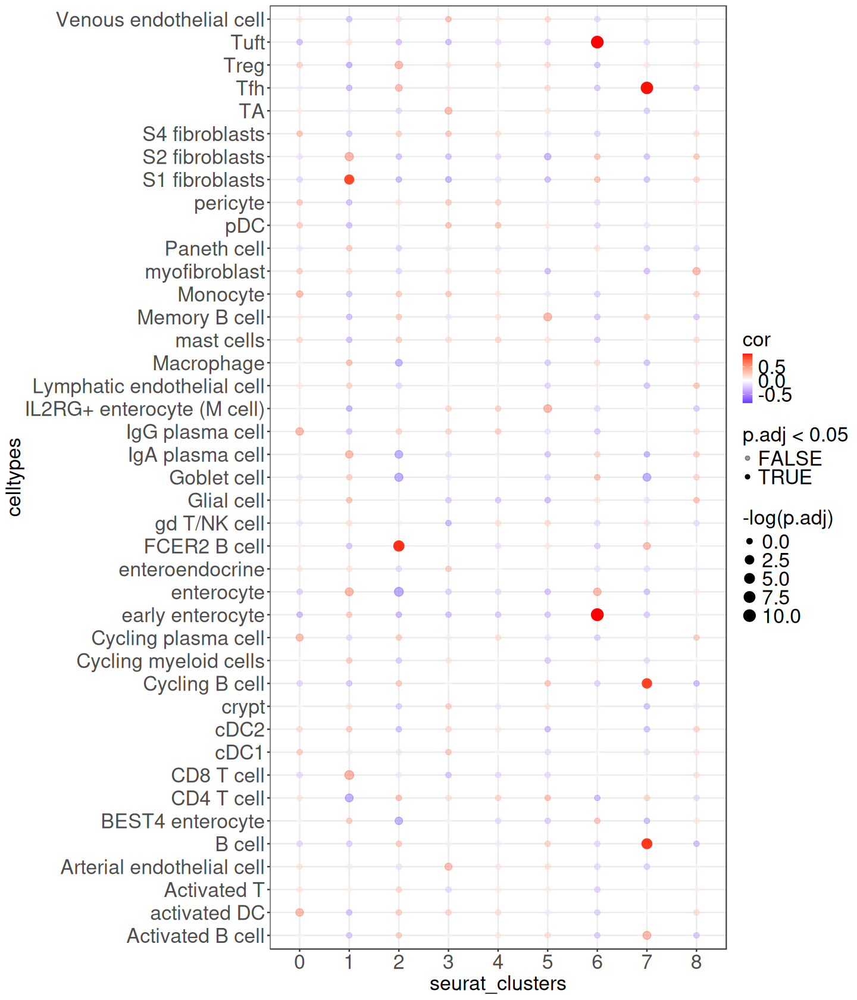

In [246]:
options(repr.plot.width = 12, repr.plot.height = 14)
stat_test_all  %>% 
ggplot(aes(x = celltypes, y = seurat_clusters)) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  coord_flip() +ggtheme()


In [247]:
mtx  <- stat_test_all  %>% 
dplyr::select(-p.adj)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = cor)  %>% 
column_to_rownames("celltypes")  %>% as.matrix

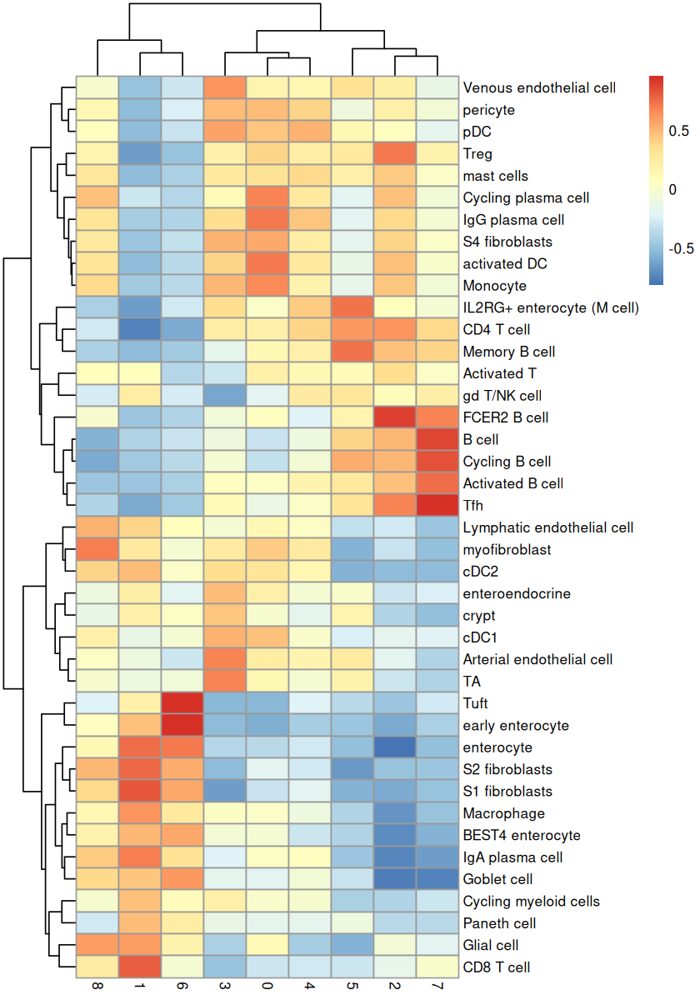

In [248]:
options(repr.plot.width = 7, repr.plot.height = 10)
res  <- pheatmap::pheatmap(mtx)

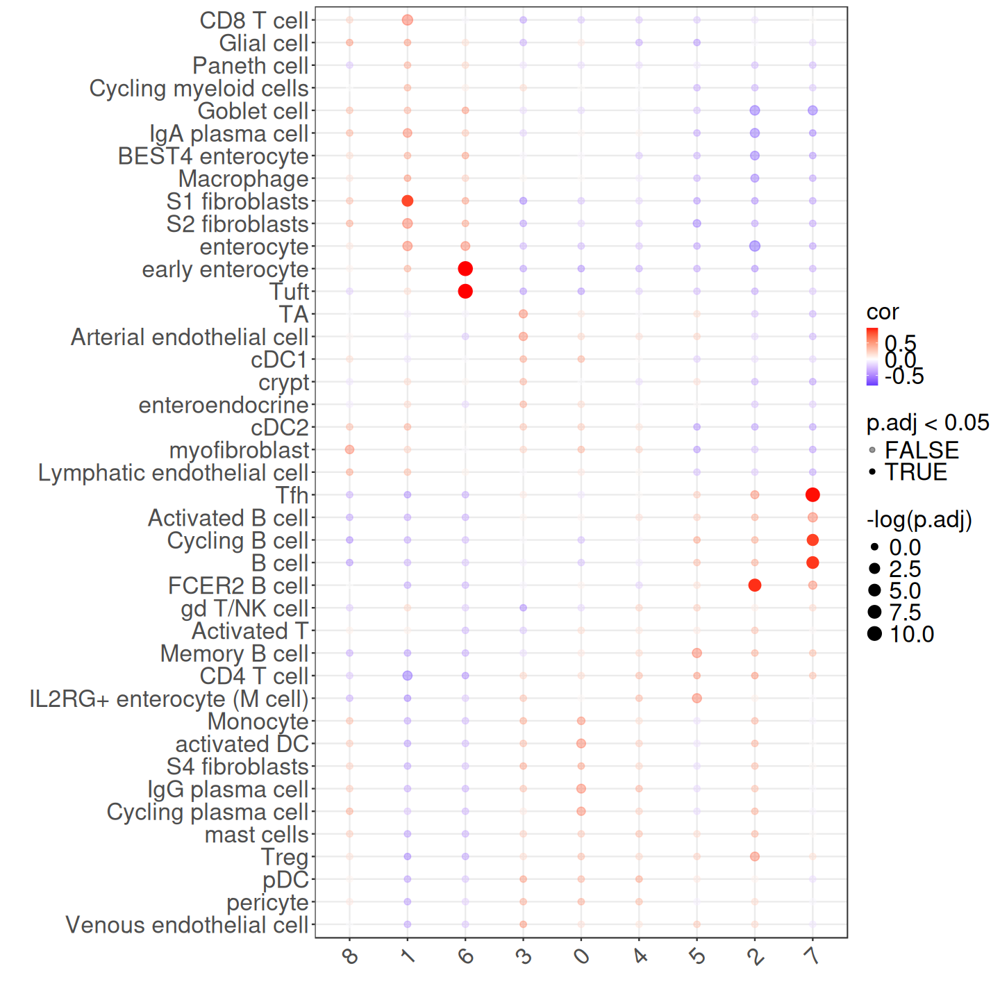

In [249]:
options(repr.plot.width = 12, repr.plot.height = 12)

stat_test_all  %>% 
ggplot(aes(x = factor(celltypes, levels = rownames(mtx)[res$tree_row$order]), 
           y = factor(seurat_clusters, levels = colnames(mtx)[res$tree_col$order]))) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  coord_flip() + ggtheme() +
ylab("") + xlab("") + theme(axis.text.x = element_text(angle = 45, hjust = 0.5, vjust = 0.5))



## Correlation - label transfer

In [250]:
df_populations  <- seu_teich@meta.data  %>% 
group_by(sample_id, annotation_V2) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
dplyr::filter(annotation_V2 != "")  %>% 
pivot_wider(names_from = annotation_V2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sample_id, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'sample_id'. You can override using the
`.groups` argument.


In [251]:
df_populations

sample_id,celltypes,freq
<chr>,<chr>,<dbl>
T017,Activated B cell,0.0009920635
T017,Activated T,0.0148809524
T017,Arterial endothelial cell,0.0357142857
T017,B cell,0.0257936508
T017,BEST4 enterocyte,0.0009920635
T017,CD4 T cell,0.1121031746
T017,CD8 T cell,0.0009920635
T017,Cycling B cell,0.0555555556
T017,Cycling plasma cell,0.0019841270


In [252]:
teich_cd4$sample_id  <- teich_cd4$`Sample name`
teich_cd4$annotation_V2  <- ref$predicted.id

In [253]:
df_tcells  <- teich_cd4@meta.data  %>% 
group_by(sample_id, annotation_V2) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
dplyr::filter(annotation_V2 != "")  %>% 
pivot_wider(names_from = annotation_V2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sample_id, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'sample_id'. You can override using the
`.groups` argument.


In [254]:
populations  <- levels(factor(df_tcells$celltypes))

In [255]:
df_populations$celltypes  %>% table  %>% length

[1] 41

In [256]:
df_populations$celltypes  %>% table

.
          Activated B cell               activated DC 
                        15                         15 
               Activated T  Arterial endothelial cell 
                        15                         15 
                    B cell           BEST4 enterocyte 
                        15                         15 
                CD4 T cell                 CD8 T cell 
                        15                         15 
                      cDC1                       cDC2 
                        15                         15 
                     crypt             Cycling B cell 
                        15                         15 
     Cycling myeloid cells        Cycling plasma cell 
                        15                         15 
          early enterocyte                 enterocyte 
                        15                         15 
           enteroendocrine               FCER2 B cell 
                        15                         15 
        

In [257]:
populations

[1] "CTL"            "Naive_1"        "Naive_2"        "Tcm"           
 [5] "Tfh"            "Th1"            "Th17_1"         "Th17_2"        
 [9] "Th2"            "Treg activated" "Treg naive"

In [269]:
i = 1
to_join <- df_tcells  %>% dplyr::filter(celltypes == levels(factor(df_tcells$celltypes))[i])  %>% 
dplyr::select(sample_id, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*41>1,1,p*41))  %>% 
dplyr::select(celltypes, p, cor)  %>% 
mutate(seurat_clusters = populations[i])

Joining with `by = join_by(sample_id)`


In [259]:
stat_test  %>% arrange(p.adj)

celltypes,p.adj,cor,seurat_clusters
<chr>,<dbl>,<dbl>,<chr>
Cycling plasma cell,1,0.5500,CTL
Monocyte,1,0.5000,CTL
activated DC,1,0.4800,CTL
IgG plasma cell,1,0.4600,CTL
Treg,1,0.4400,CTL
S4 fibroblasts,1,0.3600,CTL
Tuft,1,0.3400,CTL
Goblet cell,1,0.3200,CTL
cDC1,1,0.3000,CTL


In [260]:
populations

[1] "CTL"            "Naive_1"        "Naive_2"        "Tcm"           
 [5] "Tfh"            "Th1"            "Th17_1"         "Th17_2"        
 [9] "Th2"            "Treg activated" "Treg naive"

In [270]:
stat_test_all  <- stat_test

for(i in 2:11){
to_join <- df_tcells  %>% dplyr::filter(celltypes == levels(factor(df_tcells$celltypes))[i])  %>% 
dplyr::select(sample_id, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*41>1,1,p*41))  %>% 
dplyr::select(celltypes, p, cor)  %>% 
mutate(seurat_clusters = populations[i])

    stat_test_all  <- rbind(stat_test_all, stat_test)
}

Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`
Joining with `by = join_by(sample_id)`


In [271]:
stat_test_all  %>% arrange(p)

celltypes,p,cor,seurat_clusters
<chr>,<dbl>,<dbl>,<chr>
early enterocyte,1.68e-05,0.92,Th2
enterocyte,2.10e-05,0.92,Th17_2
Tfh,3.82e-05,0.91,Tfh
early enterocyte,6.19e-05,0.90,Th17_2
enterocyte,2.94e-04,0.86,Th2
Activated T,3.46e-04,0.86,Naive_2
enterocyte,4.57e-04,-0.85,Treg naive
S1 fibroblasts,5.22e-04,0.85,Th17_2
S1 fibroblasts,7.52e-04,0.83,Th2


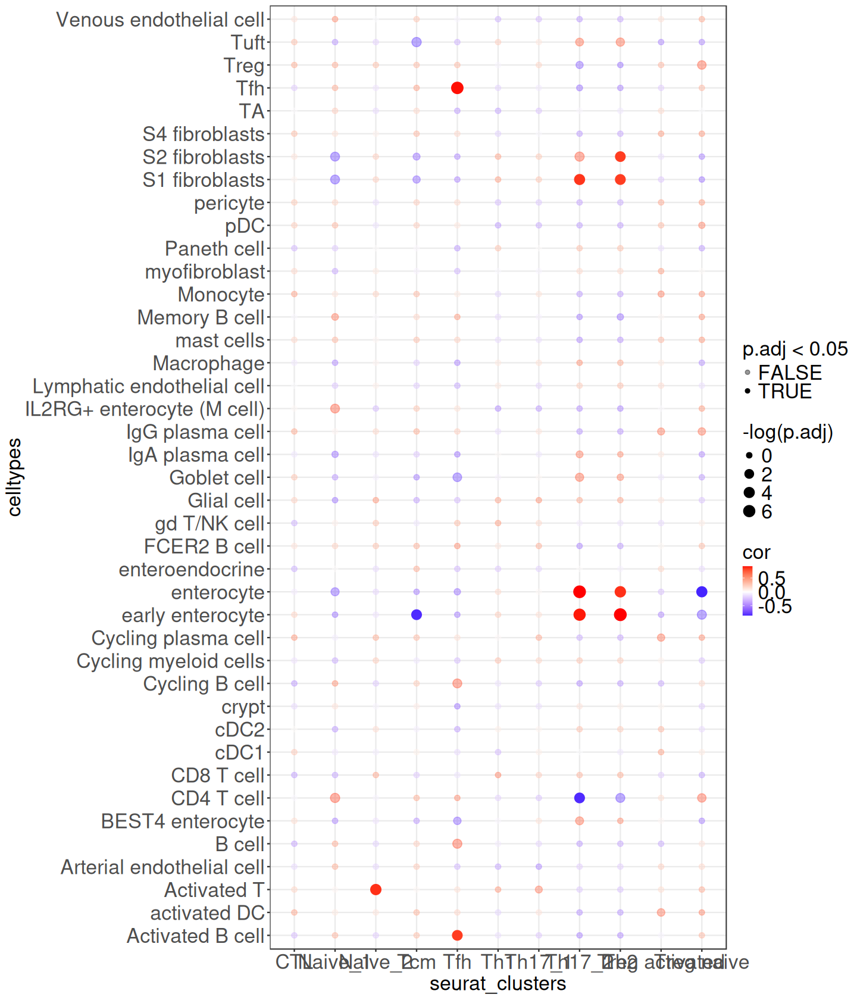

In [263]:
options(repr.plot.width = 12, repr.plot.height = 14)
stat_test_all  %>% 
ggplot(aes(x = celltypes, y = seurat_clusters)) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  coord_flip() +ggtheme()


In [264]:
mtx  <- stat_test_all  %>% 
dplyr::select(-p.adj)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = cor)  %>% 
column_to_rownames("celltypes")  %>% as.matrix

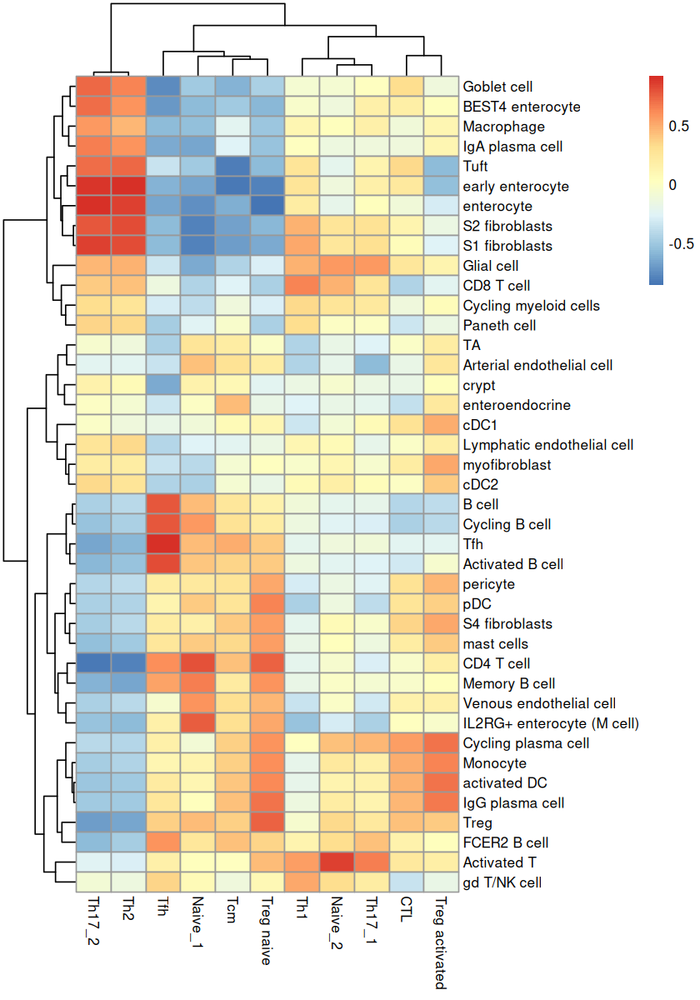

In [265]:
options(repr.plot.width = 7, repr.plot.height = 10)
res  <- pheatmap::pheatmap(mtx)

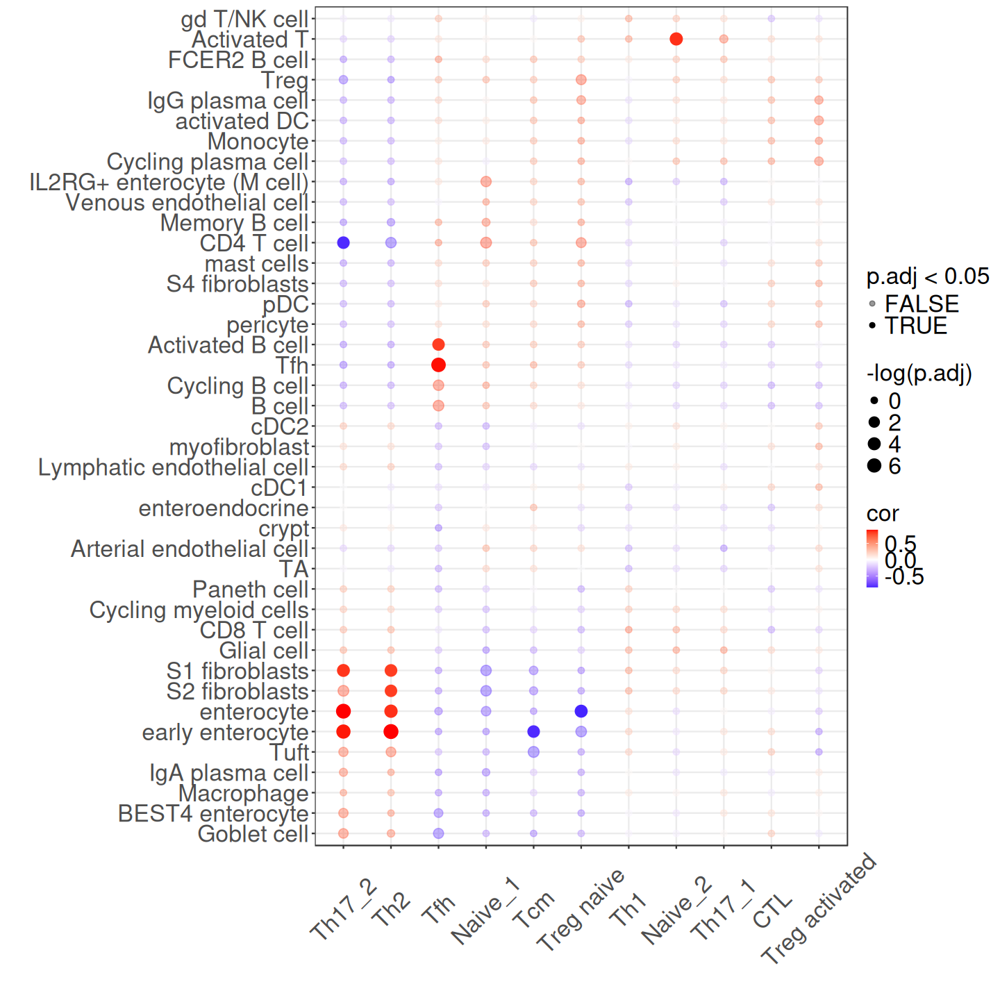

In [266]:
options(repr.plot.width = 12, repr.plot.height = 12)

stat_test_all  %>% 
ggplot(aes(x = factor(celltypes, levels = rownames(mtx)[res$tree_row$order]), 
           y = factor(seurat_clusters, levels = colnames(mtx)[res$tree_col$order]))) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  coord_flip() + ggtheme() +
ylab("") + xlab("") + theme(axis.text.x = element_text(angle = 45, hjust = 0.5, vjust = 0.5))



In [272]:
stat_test_all  %>% 
dplyr::filter(seurat_clusters == "CTL")  %>% arrange(p)

celltypes,p,cor,seurat_clusters
<chr>,<dbl>,<dbl>,<chr>
Cycling plasma cell,0.0668,0.5500,CTL
Monocyte,0.0954,0.5000,CTL
activated DC,0.1140,0.4800,CTL
IgG plasma cell,0.1350,0.4600,CTL
Cycling B cell,0.1350,-0.4600,CTL
Treg,0.1540,0.4400,CTL
CD8 T cell,0.1540,-0.4400,CTL
B cell,0.1710,-0.4200,CTL
enteroendocrine,0.2360,-0.3700,CTL


# NicheNet

In [274]:
library(nichenetr)


Attaching package: ‘nichenetr’


The following object is masked _by_ ‘.GlobalEnv’:

    lr_network




In [275]:
organism <- "human"

if(organism == "human"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_human_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final.rds"))
} else if(organism == "mouse"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_mouse_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final_mouse.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final_mouse.rds"))

}

lr_network <- lr_network %>% distinct(from, to)
head(lr_network)

from,to
<chr>,<chr>
A2M,MMP2
A2M,MMP9
A2M,LRP1
A2M,KLK3
AANAT,MTNR1A
AANAT,MTNR1B


In [278]:
seu_teich$annotation_V2  %>% table

.
          Activated B cell               activated DC 
                       218                         43 
               Activated T  Arterial endothelial cell 
                       301                        355 
                    B cell           BEST4 enterocyte 
                       845                        119 
                CD4 T cell                 CD8 T cell 
                      1258                        340 
                      cDC1                       cDC2 
                        61                        337 
                     crypt             Cycling B cell 
                      1190                        865 
     Cycling myeloid cells        Cycling plasma cell 
                        40                         78 
          early enterocyte                 enterocyte 
                       837                       4112 
           enteroendocrine               FCER2 B cell 
                        71                       1001 
        

In [280]:
seu_teich$keep  <- !(seu_teich$annotation_V2 %in% c("Treg","Activated T","CD4 T cell","Tfh"))

In [281]:
teich_without_cd4  <- subset(seu_teich, keep == TRUE)

In [282]:
teich_without_cd4$annotation_V2  %>% table

.
          Activated B cell               activated DC 
                       218                         43 
 Arterial endothelial cell                     B cell 
                       355                        845 
          BEST4 enterocyte                 CD8 T cell 
                       119                        340 
                      cDC1                       cDC2 
                        61                        337 
                     crypt             Cycling B cell 
                      1190                        865 
     Cycling myeloid cells        Cycling plasma cell 
                        40                         78 
          early enterocyte                 enterocyte 
                       837                       4112 
           enteroendocrine               FCER2 B cell 
                        71                       1001 
              gd T/NK cell                 Glial cell 
                       490                         28 
        

In [283]:
teich_cd4$annotation_V2  <- paste0("CD4_subcluster_",teich_cd4$seurat_clusters)

In [304]:
teich_cd4$annotation_V1  <- "CD4"

In [293]:
teich_without_cd4$annotation_V1  <- teich_without_cd4$annotation_V2

In [294]:
teich_and_cd4  <- merge(teich_without_cd4, teich_cd4)

In [287]:
teich_and_cd4$annotation_V2  %>% table

.
          Activated B cell               activated DC 
                       218                         43 
 Arterial endothelial cell                     B cell 
                       355                        845 
          BEST4 enterocyte           CD4_subcluster_0 
                       119                       1112 
          CD4_subcluster_1           CD4_subcluster_2 
                      1109                       1057 
          CD4_subcluster_3           CD4_subcluster_4 
                       994                        936 
          CD4_subcluster_5           CD4_subcluster_6 
                       933                        778 
          CD4_subcluster_7           CD4_subcluster_8 
                       615                        331 
                CD8 T cell                       cDC1 
                       340                         61 
                      cDC2                      crypt 
                       337                       1190 
        

In [288]:
Idents(teich_and_cd4)  <- teich_and_cd4$annotation_V2

In [289]:
receiver = "CD4_subcluster_8"
expressed_genes_receiver <- get_expressed_genes(receiver, teich_and_cd4, pct = 0.05)

In [290]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [296]:
Idents(teich_and_cd4)  <- teich_and_cd4$annotation_V1

In [297]:
sender_celltypes <- levels(factor(teich_and_cd4$annotation_V1))

# Use lapply to get the expressed genes of every sender cell type separately here
list_expressed_genes_sender <- sender_celltypes %>% unique() %>% lapply(get_expressed_genes, teich_and_cd4, 0.05)
expressed_genes_sender <- list_expressed_genes_sender %>% unlist() %>% unique()

potential_ligands_focused <- intersect(potential_ligands, expressed_genes_sender) 

# Also check 
length(expressed_genes_sender)
## [1] 8492
length(potential_ligands)
## [1] 483
length(potential_ligands_focused)
## [1] 127

[1] 16042

[1] 528

[1] 365

In [298]:
teich_and_cd4$Diagnosis  %>% table

.
          Crohn Disease          Normal control Pediatric Crohn Disease 
                  10099                   10475                    5138 
      Pediatric healthy 
                   2727 

In [299]:
seu_teich$Diagnosis  %>% table

.
 Crohn Disease Normal control 
         11200          11302 

In [301]:
teich_and_cd4$disease  <- ifelse(teich_and_cd4$Diagnosis %in% c("Crohn Disease", "Pediatric Crohn Disease"),"CD","HD")

In [302]:
teich_and_cd4$disease  %>% table

.
   CD    HD 
15237 13202 

In [303]:
teich_and_cd4$annotation_V1  %>% table

.
          Activated B cell               activated DC 
                       218                         43 
 Arterial endothelial cell                     B cell 
                       355                        845 
          BEST4 enterocyte                        CD4 
                       119                       7865 
                CD8 T cell                       cDC1 
                       340                         61 
                      cDC2                      crypt 
                       337                       1190 
            Cycling B cell      Cycling myeloid cells 
                       865                         40 
       Cycling plasma cell           early enterocyte 
                        78                        837 
                enterocyte            enteroendocrine 
                      4112                         71 
              FCER2 B cell               gd T/NK cell 
                      1001                        490 
        

In [306]:
condition_oi <-  "CD"
condition_reference <- "HD"

seurat_obj_receiver <- subset(teich_and_cd4, annotation_V1 == "CD4")

DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "disease",
                                  min.pct = 0.05) %>% rownames_to_column("gene")

geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% pull(gene)
geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]

In [307]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

[1] 4871

[1] 247

In [308]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

In [309]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
JAM2,0.6264647,0.1185223,0.06810386,0.12866834
CCL3,0.6160238,0.1152617,0.06484324,0.11330126
ICAM1,0.6061913,0.1113424,0.06092396,0.11521739
CCL20,0.6156970,0.1110356,0.06061712,0.09588874
IL4,0.6403571,0.1102305,0.05981204,0.14178152
ADAM29,0.6104853,0.1100046,0.05958616,0.11059241
GCG,0.6045330,0.1090644,0.05864598,0.10181399
MMP9,0.6105615,0.1086924,0.05827395,0.10399368
DEFB103B,0.6080594,0.1076941,0.05727560,0.11608944


In [310]:
ligand_activities  %>% pull(test_ligand)

[1] "JAM2"      "CCL3"      "ICAM1"     "CCL20"     "IL4"       "ADAM29"   
  [7] "GCG"       "MMP9"      "DEFB103B"  "COL4A5"    "PTPRC"     "JAML"     
 [13] "CCL3L3"    "AGRN"      "JAM3"      "IFNA8"     "LPA"       "LAMB3"    
 [19] "HLA-DOA"   "CCL4"      "HLA-DRA"   "CCL26"     "IL13"      "PDCD1LG2" 
 [25] "KIR2DL5A"  "CCL7"      "CXCL10"    "IL12A"     "CD28"      "KNG1"     
 [31] "IFNA4"     "COL19A1"   "IL2"       "CD22"      "ADAM11"    "CCL3L1"   
 [37] "IL16"      "FGA"       "CCL16"     "FGG"       "CD80"      "THBS4"    
 [43] "CCL4L2"    "HBEGF"     "CXCL13"    "CCL4L1"    "BTLA"      "COL18A1"  
 [49] "COL9A2"    "B2M"       "FGF2"      "CXCL11"    "PYY"       "FCAR"     
 [55] "HSPG2"     "CEACAM1"   "CCL22"     "CXCL16"    "CCL8"      "PIP"      
 [61] "IL36G"     "ICAM3"     "CXCL14"    "SIGLEC7"   "PECAM1"    "PF4V1"    
 [67] "IFNA10"    "GP5"       "HLA-DQB1"  "SIGLEC9"   "HAVCR1"    "SIGLEC14" 
 [73] "SFTPD"     "COL11A2"   "GHRH"      "LILRB2"    "ADAM7"     "CCL23"    
 [79] "IL10"      "NECTIN1"   "APOA1"     "MMP1"      "IL1F10"    "MXRA5"    
 [85] "DEFB4A"    "LGALS3"    "MELTF"     "IFNA21"    "ANGPTL1"   "CCL21"    
 [91] "SDC2"      "CLMP"      "COL6A2"    "PLAT"      "COL20A1"   "SPP1"     
 [97] "ADAM17"    "CCN6"      "TRAF2"     "COL15A1"   "LUM"       "TNFSF9"   
[103] "SELL"      "IFNA17"    "CD40"      "CCL19"     "CXCL9"     "FASLG"    
[109] "BDNF"      "FGB"       "HLA-DRB3"  "LAMC3"     "HP"        "CLEC2L"   
[115] "EDIL3"     "HLA-DQA1"  "ANGPT2"    "HLA-DRB5"  "OCLN"      "GP1BA"    
[121] "SELP"      "PVR"       "CCL5"      "MFAP2"     "CNTN6"     "LRRC4B"   
[127] "LGALS3BP"  "CD160"     "L1CAM"     "PENK"      "TGFA"      "PLG"      
[133] "ADAM2"     "IFNA6"     "GPC3"      "COL27A1"   "CCL2"      "CCN3"     
[139] "VSIG10"    "CCL1"      "MMP14"     "TNN"       "PRSS3"     "LAMA3"    
[145] "THY1"      "KCNA1"     "TIMP1"     "CNTN1"     "CD48"      "CCL18"    
[151] "CCL13"     "CD86"      "COL6A6"    "ITGB2"     "CD99"      "CXCL2"    
[157] "SIRPA"     "IFNK"      "CD40LG"    "F2"        "COL5A3"    "TGFBI"    
[163] "SIGLEC5"   "HGF"       "INHA"      "HLA-DMB"   "VEGFD"     "NTM"      
[169] "LIPH"      "ADAM9"     "LIF"       "IL9"       "PLA2G2A"   "HLA-DRB4" 
[175] "IFNW1"     "LCN1"      "NAMPT"     "CEACAM6"   "SDC4"      "CD1B"     
[181] "CXADR"     "FN1"       "TIMP2"     "COL8A1"    "CD82"      "APOA2"    
[187] "LAMB2"     "TNC"       "LAMA5"     "DSPP"      "COL28A1"   "GDF2"     
[193] "COL1A2"    "CD44"      "PF4"       "COL14A1"   "VTN"       "CHAD"     
[199] "HLA-DQB2"  "SIRPB2"    "LAMA1"     "CD244"     "LRFN5"     "VCAN"     
[205] "HLA-DPB1"  "F8"        "GGT1"      "F11R"      "C3"        "COL6A3"   
[211] "IL3"       "CD2"       "ICAM4"     "DUSP18"    "AMELY"     "GZMB"     
[217] "CD72"      "IFNA13"    "FBN1"      "LAMC2"     "COL6A5"    "COL4A4"   
[223] "COL8A2"    "IFNA7"     "APOE"      "MMP2"      "COL3A1"    "GSTP1"    
[229] "VCAM1"     "IL12B"     "TF"        "FCER2"     "LAMB1"     "COL13A1"  
[235] "ICAM2"     "APOA4"     "HAS2"      "NTF4"      "CD70"      "REN"      
[241] "SLPI"      "MICB"      "LGALS1"    "COL9A3"    "ICAM5"     "NCR3LG1"  
[247] "CCL11"     "S100A8"    "JAG2"      "HLA-DQA2"  "MDK"       "COL4A6"   
[253] "S100A9"    "MATN1"     "ZG16B"     "CD58"      "COL4A2"    "CD200"    
[259] "CDH1"      "CD47"      "CD209"     "PCSK9"     "TNFSF4"    "THBS1"    
[265] "PRSS1"     "COL7A1"    "CLEC3A"    "ADAM15"    "IL6"       "PLXNA1"   
[271] "LAMC1"     "APOB"      "TNXB"      "DEFB1"     "HLA-DRB1"  "NPPB"     
[277] "F10"       "HAS1"      "FURIN"     "CCL15"     "IL7"       "CD55"     
[283] "ORM1"      "COL4A3"    "FAM3C"     "VSTM1"     "COL5A2"    "IFNA14"   
[289] "CRHR2"     "CTSG"      "COL17A1"   "F13A1"     "TSLP"      "COL21A1"  
[295] "NETO2"     "COL12A1"   "SIGLEC8"   "COL24A1"   "CD320"     "LRPAP1"   
[301] "RELN"      "IFNA5"     "RAET1E"    "PROC"      "ICOSLG"    "CTF1"     
[307] "CCL14"     "COL9A

`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


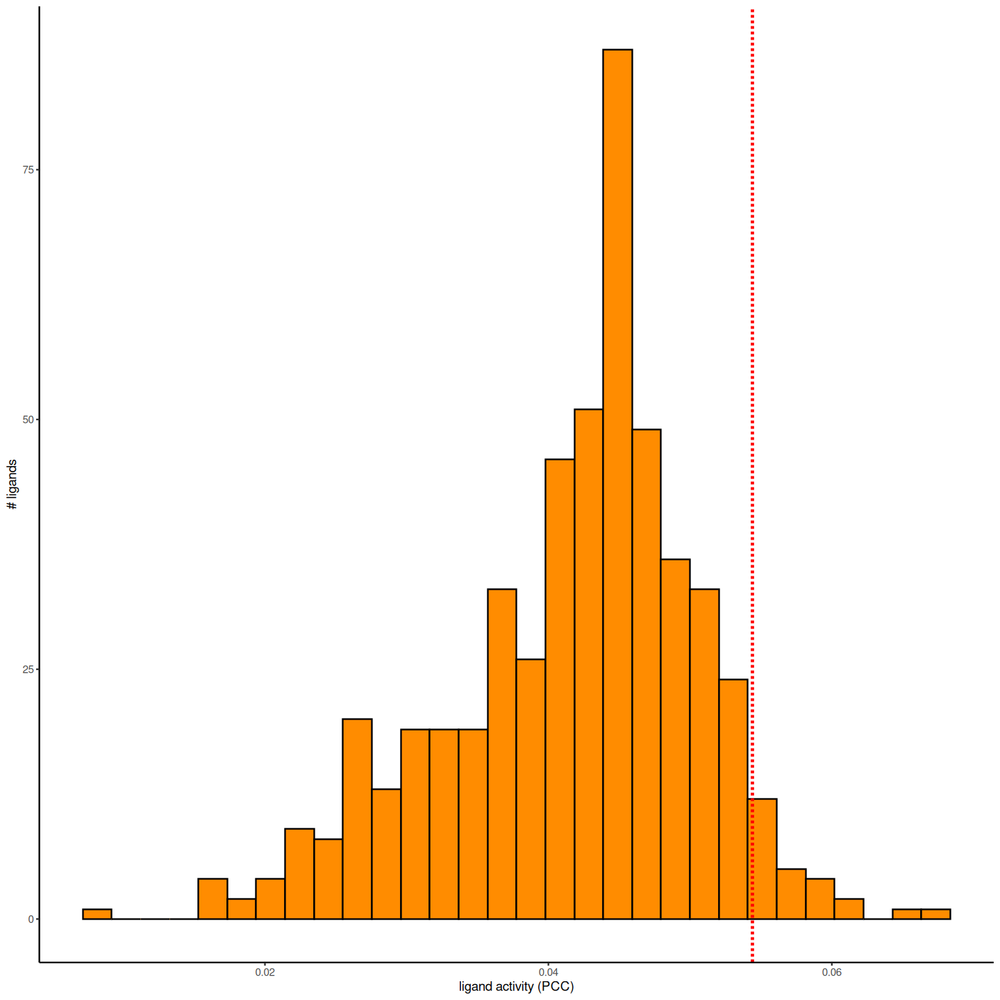

In [314]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(20, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [315]:
best_upstream_ligands <- ligand_activities %>% top_n(20, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [316]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

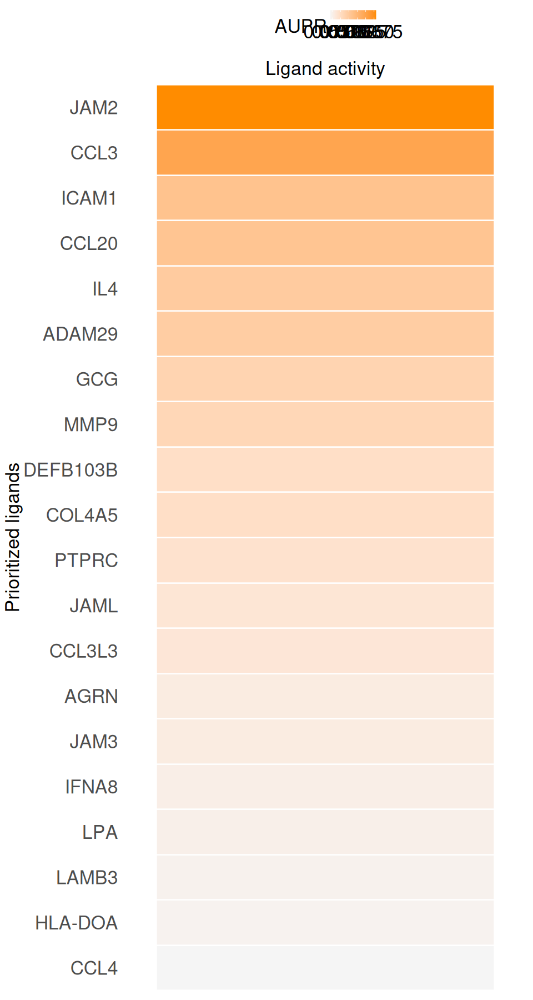

In [317]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()